# EDA Datavidia 11.0 Task 1: status penanganan pengiriman

## 0. Setup

In [34]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency
from IPython.display import display, HTML

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 200)

BASE = "dataset/Task-1-Datavidia-11.0/"
TARGET = "status_penanganan"

In [35]:
shipments = pd.read_csv(BASE + "train/shipments.csv")
courier   = pd.read_csv(BASE + "train/couriers.csv")
custom    = pd.read_csv(BASE + "train/customers.csv")
hubs      = pd.read_csv(BASE + "train/hubs.csv")
invoices  = pd.read_csv(BASE + "train/invoices.csv")
promo     = pd.read_csv(BASE + "train/promotions.csv")
route     = pd.read_csv(BASE + "train/route_segments.csv")
event     = pd.read_csv(BASE + "train/scan_events.csv",
                        dtype={"event_type": "category", "device_type": "category"})
service   = pd.read_csv(BASE + "train/service_packages.csv")

kolom_asli = list(shipments.columns)

In [36]:
def show(df, judul=None):
    if judul:
        display(HTML(f"<h4>{judul}</h4>"))
    display(HTML(df.to_html(border=1)))


def eta_sq(df, cols):
    g = df.groupby(TARGET)[cols]
    n, mu = g.count(), g.mean()
    grand = df[cols].mean()
    ssb = (n * (mu - grand) ** 2).sum()
    sst = ((df[cols] - grand) ** 2).sum()
    return (ssb / sst).sort_values(ascending=False)


def cramers_v(x, y):
    ct = pd.crosstab(x, y)
    chi2 = chi2_contingency(ct, correction=False)[0]
    return np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))


def cat_report(df, col, urut="n", maks=15, min_n=1000):
    ct = pd.crosstab(df[col], df[TARGET], normalize="index")
    n = df[col].value_counts().rename("n")
    tab = pd.concat([n, ct], axis=1)
    tab = tab.sort_values("n", ascending=False) if urut == "n" else tab.sort_index()
    fmt = tab.head(maks).copy()
    fmt["n"] = fmt["n"].map("{:,.0f}".format)
    for k in ct.columns:
        fmt[k] = fmt[k].map("{:.1%}".format)
    show(fmt, f"{col} (V = {cramers_v(df[col], df[TARGET]):.4f})")
    base = df[TARGET].value_counts(normalize=True)
    ok = n[n >= min_n].index
    if len(ok):
        lift = (ct / base).loc[ok]
        show(pd.DataFrame({"lift_maks": lift.max().round(2), "di_level": lift.idxmax()}), f"lift {col}")


def bin_report(df, col, q=10):
    tmp = pd.DataFrame({col: pd.qcut(df[col], q, duplicates="drop"), TARGET: df[TARGET]})
    cat_report(tmp, col, urut="index", maks=q)


def signal_map(df, cols, q=10, min_n=5000):
    base = df[TARGET].value_counts(normalize=True)
    rows = []
    for col in cols:
        x = df[col]
        if pd.api.types.is_numeric_dtype(x) and x.nunique() > 30:
            x = pd.qcut(x, q, duplicates="drop")
        ct = pd.crosstab(x, df[TARGET], normalize="index")
        n = x.value_counts()
        ct = ct.loc[n[n >= min_n].index]
        if len(ct) < 2:
            continue
        lift = (ct / base).clip(lower=0.01)
        for k in lift.columns:
            rows.append((col, k, lift[k].max(), lift[k].min()))
    out = pd.DataFrame(rows, columns=["fitur", "kelas", "lift_maks", "lift_min"])
    out["rasio"] = out.lift_maks / out.lift_min
    return out.sort_values("rasio", ascending=False).round(2).reset_index(drop=True)


def ringkas(cols, k=3):
    sm = signal_map(df, cols)
    top = sm.sort_values(["kelas", "rasio"], ascending=[True, False]).groupby("kelas").head(k)
    show(top.reset_index(drop=True), "fitur terkuat per kelas")

## 1. Ringkasan dataset

In [37]:
datasets = {"courier": courier, "customers": custom, "hubs": hubs, "invoices": invoices,
            "promotions": promo, "route_segments": route, "scan_events": event,
            "service_packages": service, "shipments": shipments}
ringkasan = pd.DataFrame({
    "baris": {k: len(v) for k, v in datasets.items()},
    "kolom": {k: v.shape[1] for k, v in datasets.items()},
    "missing": {k: int(v.isna().sum().sum()) for k, v in datasets.items()},
})
show(ringkasan)

,baris,kolom,missing
courier,23806,11,256
customers,573841,14,11429
hubs,654,9,0
invoices,1467722,12,622355
promotions,34,6,0
route_segments,2200148,8,43968
scan_events,6837111,8,0
service_packages,62,10,0
shipments,1243617,38,37012


Kesimpulan:

`volume_l` (shipments, 3,0%), `courier_score` (1,1%), `credit_score` (2,0%), `discount` (invoice, 42,4%) dan `durasi_jam` (rute, 2,0%). Dengan 1,24 juta pengiriman, rata-rata tiap pengiriman punya sekitar 5,5 scan, 1,8 segmen rute dan 1,2 invoice, jadi tabel anak harus diringkas dulu per pengiriman sebelum dipakai.

### Visualisasi Section 1: Ringkasan dataset

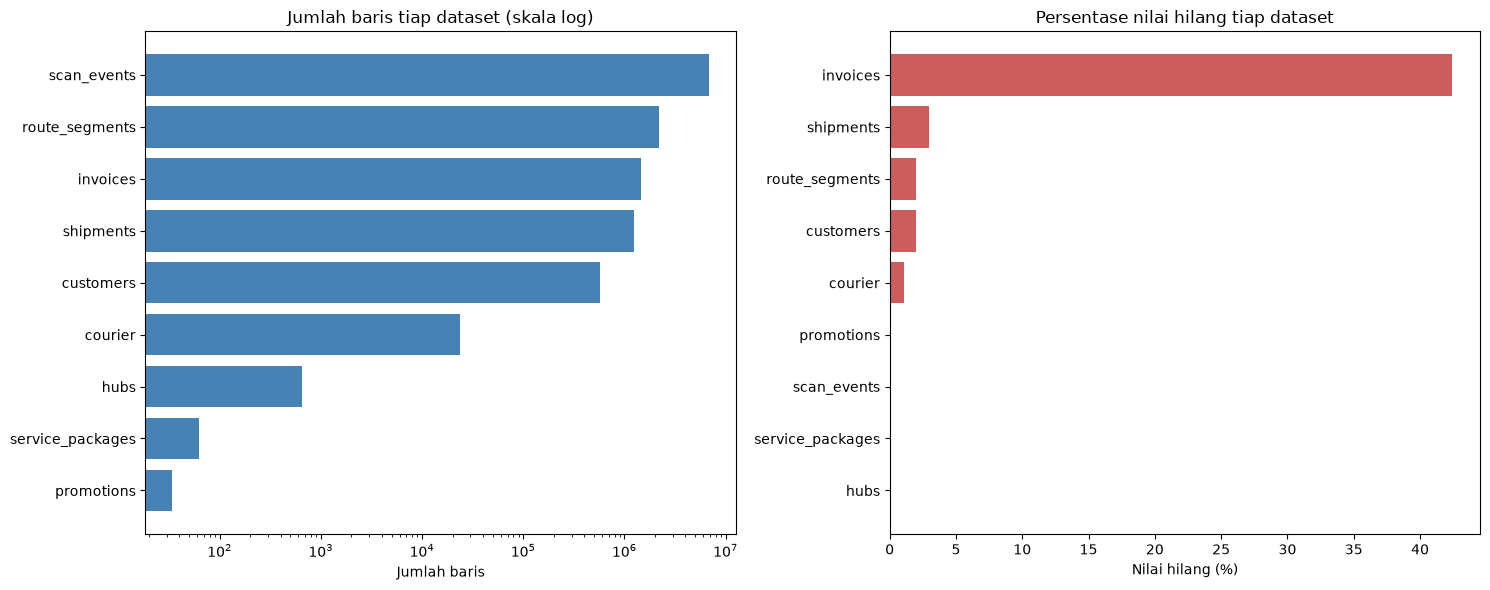

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
baris = ringkasan["baris"].sort_values()
y = np.arange(len(baris))
axes[0].scatter(baris.values, y, s=70, color="steelblue")
axes[0].set_xscale("log")
axes[0].set_yticks(y, baris.index)
axes[0].set_title("Jumlah baris tiap dataset (skala log)")
axes[0].set_xlabel("Jumlah baris")
axes[0].grid(axis="x", alpha=0.25)
missing_pct = (ringkasan["missing"] / ringkasan["baris"] * 100).sort_values()
im = axes[1].imshow(missing_pct.to_numpy().reshape(1, -1), aspect="auto", cmap="Reds", vmin=0)
axes[1].set_yticks([0], ["Missing"])
axes[1].set_xticks(range(len(missing_pct)), missing_pct.index, rotation=45, ha="right")
axes[1].set_title("Persentase nilai hilang tiap dataset")
for x, value in enumerate(missing_pct.values):
    axes[1].text(x, 0, f"{value:.1f}%", ha="center", va="center", fontsize=8,
                 color="white" if value > missing_pct.max() * 0.55 else "black")
fig.colorbar(im, ax=axes[1], label="Missing (%)", fraction=0.046, pad=0.04)
fig.tight_layout()
plt.show()


## 2. Distribusi target

,n,persen
status_penanganan,,
normal,473531,38.08
konfirmasi_alamat,272911,21.94
tertunda_operasional,185496,14.92
gagal_antar_awal,124341,10.00
retur_pengirim,87740,7.06
rusak_perjalanan,61942,4.98
klaim_hilang,37656,3.03


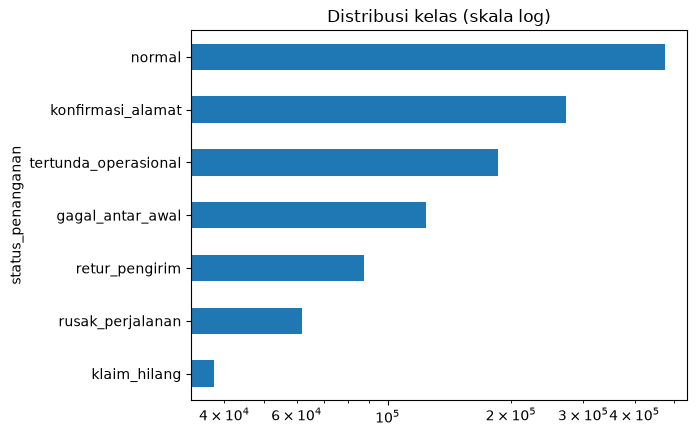

In [39]:
vc = shipments[TARGET].value_counts()
show(pd.DataFrame({"n": vc, "persen": (100 * vc / len(shipments)).round(2)}))
vc.sort_values().plot.barh(logx=True, title="Distribusi kelas (skala log)")
plt.show()

Kesimpulan:

normal 38,1%, konfirmasi_alamat 21,9%, tertunda_operasional 14,9%, gagal_antar_awal 10,0%, retur_pengirim 7,1%, rusak_perjalanan 5,0%, klaim_hilang 3,0%. Rasio kelas terbesar terhadap terkecil 12,6:1 dan kelas terkecil masih punya 37.656 baris, jadi ketidakseimbangannya sedang dan tidak perlu resampling. Menebak semua normal hanya benar 38%. Karena Macro F1 memberi bobot sama ke tiap kelas, validasi dibuat stratified dan bobot atau ambang per kelas dituning di akhir.

### Visualisasi Section 2: Distribusi target

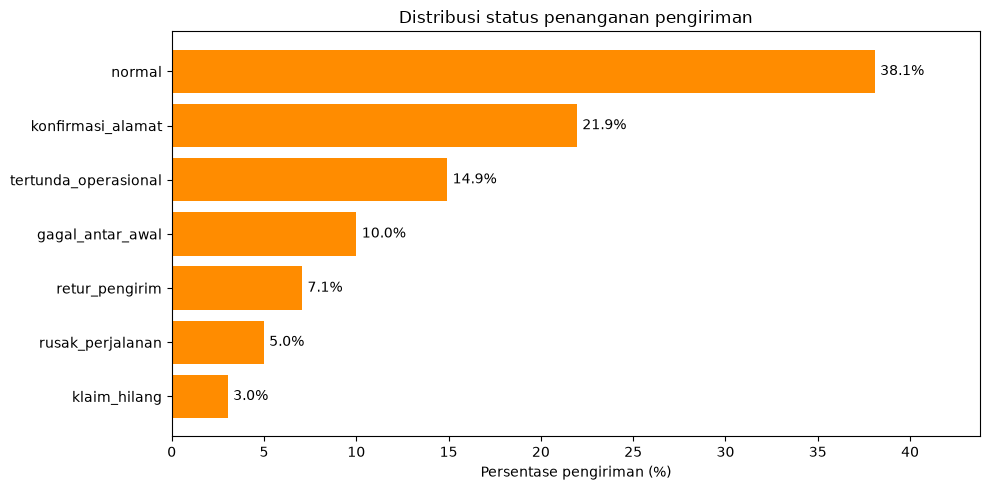

In [40]:
target_counts = shipments[TARGET].value_counts()
labels = [f"{kelas} ({jumlah / len(shipments):.1%})" for kelas, jumlah in target_counts.items()]
fig, ax = plt.subplots(figsize=(9, 7))
wedges, _ = ax.pie(target_counts.values, startangle=90, counterclock=False,
                   wedgeprops={"width": 0.42, "edgecolor": "white"},
                   colors=plt.cm.Set2(np.linspace(0, 1, len(target_counts))))
ax.text(0, 0, f"Total\n{len(shipments):,}", ha="center", va="center", fontsize=13)
ax.legend(wedges, labels, title="Status penanganan", loc="center left",
          bbox_to_anchor=(1, 0.5), frameon=False)
ax.set_title("Komposisi status penanganan pengiriman")
ax.set_aspect("equal")
fig.tight_layout()
plt.show()


## 3. Kualitas data shipments

In [41]:
kosong = 100 * shipments.isna().mean()
print(kosong[kosong > 0].round(3))
print("duplikat shipment_id:", shipments.shipment_id.duplicated().sum())
show(pd.crosstab(shipments.promo_id.eq("TANPA_PROMO"), shipments.is_promo), "TANPA_PROMO vs is_promo")
show((100 * shipments.groupby(TARGET)["volume_l"].apply(lambda s: s.isna().mean())).round(3).to_frame("volume_l kosong (%)"))

volume_l    2.976
dtype: float64
duplikat shipment_id: 0


is_promo,0,1
promo_id,,
False,0,211209
True,1032408,0


,volume_l kosong (%)
status_penanganan,
gagal_antar_awal,2.989
klaim_hilang,2.892
konfirmasi_alamat,3.032
normal,2.947
retur_pengirim,2.935
rusak_perjalanan,2.975
tertunda_operasional,2.997


Kesimpulan

Hanya `volume_l` yang kosong (2,98%) dan tidak ada duplikat. Kosongnya tersebar merata di semua kelas (2,89% sampai 3,03%), jadi bukan sinyal dan cukup dibiarkan NaN untuk model berbasis pohon. `is_promo` sama persis dengan `promo_id != "TANPA_PROMO"` (17% pengiriman berpromo), jadi cukup dipakai salah satu.

### Visualisasi Section 3: Kualitas data shipments

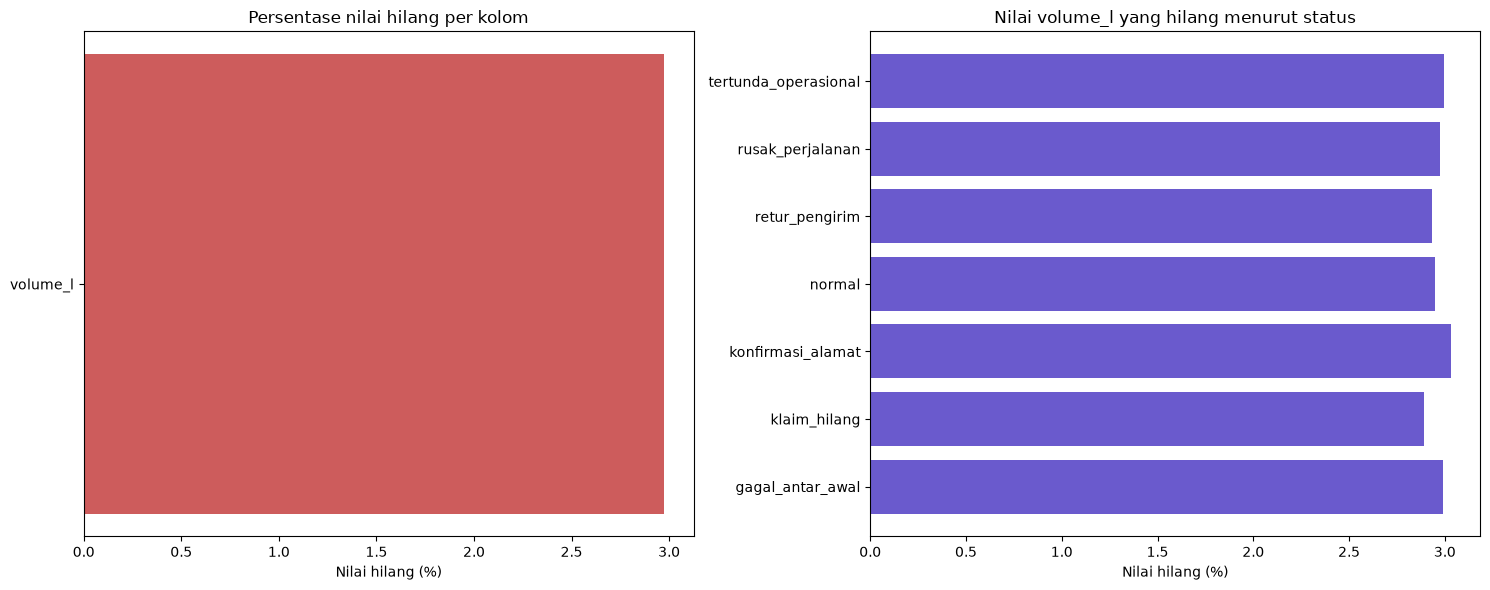

In [42]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
missing_col = kosong[kosong > 0].sort_values()
y = np.arange(len(missing_col))
axes[0].hlines(y, 0, missing_col.values, color="lightcoral", linewidth=2)
axes[0].scatter(missing_col.values, y, color="firebrick", s=55, zorder=3)
axes[0].set_yticks(y, missing_col.index)
axes[0].set_title("Persentase nilai hilang per kolom")
axes[0].set_xlabel("Nilai hilang (%)")
axes[0].grid(axis="x", alpha=0.25)
promo_match = pd.crosstab(
    shipments.promo_id.eq("TANPA_PROMO").map({True: "Tanpa promo", False: "Ada promo"}),
    shipments.is_promo, normalize="index",
) * 100
im = axes[1].imshow(promo_match.values, cmap="Blues", vmin=0, vmax=100, aspect="auto")
axes[1].set_yticks(range(len(promo_match.index)), promo_match.index)
axes[1].set_xticks(range(len(promo_match.columns)), [f"is_promo={v}" for v in promo_match.columns])
axes[1].set_title("Konsistensi promo_id dengan is_promo")
for row in range(promo_match.shape[0]):
    for col in range(promo_match.shape[1]):
        value = promo_match.iloc[row, col]
        axes[1].text(col, row, f"{value:.1f}%", ha="center", va="center",
                     color="white" if value > 55 else "black")
fig.colorbar(im, ax=axes[1], label="Proporsi dalam baris (%)", fraction=0.046, pad=0.04)
fig.tight_layout()
plt.show()


## 4. Shipments: numerik vs target

In [43]:
num_cols = shipments[kolom_asli].select_dtypes("number").columns.tolist()
eta = eta_sq(shipments, num_cols)
show(eta.round(5).to_frame("eta2"), "Eta kuadrat")
show(shipments.groupby(TARGET)[eta.index[:12].tolist()].mean().T.round(2), "Rata-rata per kelas, 12 teratas")

,eta2
jumlah_catatan,0.06427
declared_value,0.05886
distance_km,0.03483
flag_alamat_baru,0.01283
ship_month,0.00580
is_cod,0.00068
order_to_ship_hours,0.00018
prioritas_pengiriman,0.00013
skor_kualitas_cek,0.00001
insurance_opt,0.00001


status_penanganan,gagal_antar_awal,klaim_hilang,konfirmasi_alamat,normal,retur_pengirim,rusak_perjalanan,tertunda_operasional
jumlah_catatan,0.49,0.38,0.77,0.36,0.46,0.37,0.41
declared_value,131354.85,411054.97,134808.95,116181.77,122482.65,131953.04,132438.61
distance_km,856.23,872.04,893.30,842.30,889.37,1174.44,959.31
flag_alamat_baru,0.14,0.11,0.20,0.10,0.13,0.11,0.11
ship_month,6.71,6.69,6.74,6.59,6.74,6.70,7.39
is_cod,0.06,0.06,0.06,0.06,0.09,0.06,0.06
order_to_ship_hours,6.69,6.68,6.68,6.64,6.67,6.68,6.86
prioritas_pengiriman,1.65,1.64,1.64,1.64,1.65,1.64,1.66
skor_kualitas_cek,50.01,50.14,49.98,49.95,50.00,50.06,50.04
insurance_opt,0.55,0.54,0.55,0.54,0.55,0.55,0.55


In [44]:
anon = ["skor_prioritas_kirim", "indeks_rute_sekunder", "faktor_muatan_internal",
        "varian_cuaca_rute", "indeks_waktu_proses", "skor_kualitas_cek"]
show(shipments.groupby(TARGET)[anon].agg(["mean", "std"]).round(2).T, "Enam kolom anonim per kelas")

Kesimpulan

Sinyal numerik hanya ada di `jumlah_catatan` (0,064), `declared_value` (0,059), `distance_km` (0,035), `flag_alamat_baru` (0,013) dan `ship_month` (0,006). Sisanya hampir nol. Enam kolom anonim punya mean sekitar 50 dan std sekitar 12 di setiap kelas, jadi kemungkinan besar noise dan dibuang dari baseline, lalu dicek ulang lewat permutation importance.

Eta kuadrat hanya melihat beda rata-rata dan dirata-ratakan lintas kelas. Fitur yang hanya menggeser satu kelas langka (misalnya `is_cod` ke retur_pengirim) tampak lemah di sini padahal berguna, jadi jangan menyaring fitur hanya dari angka ini.

### Visualisasi Section 4: Fitur numerik vs target

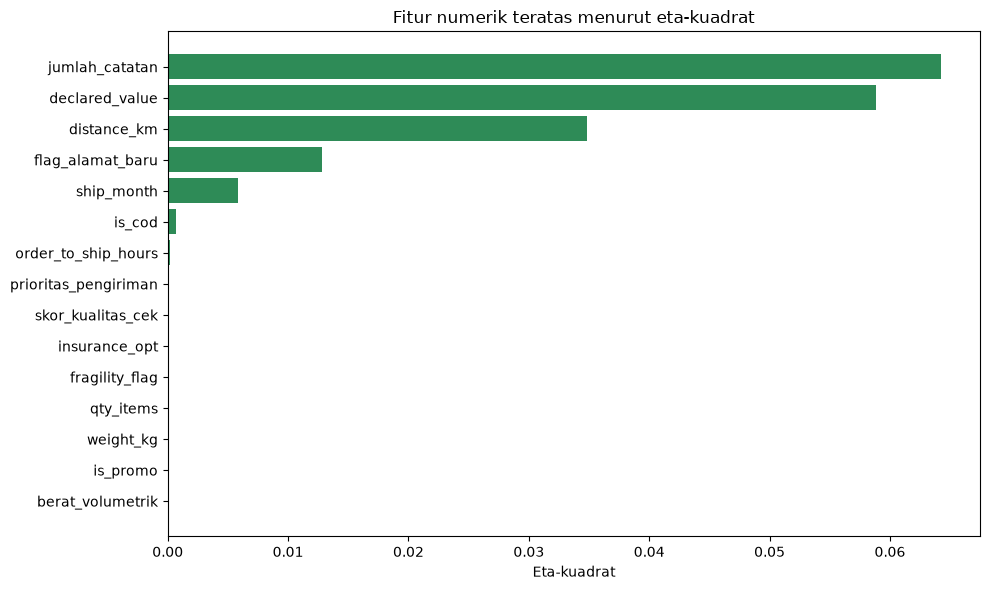

In [45]:
eta_top = eta.head(12)
mean_per_class = shipments.groupby(TARGET)[eta_top.index].mean().T
mean_z = mean_per_class.sub(mean_per_class.mean(axis=1), axis=0).div(
    mean_per_class.std(axis=1).replace(0, np.nan), axis=0
).fillna(0)
fig, axes = plt.subplots(1, 2, figsize=(17, 7), gridspec_kw={"width_ratios": [1.15, 1]})
im = axes[0].imshow(mean_z.values, aspect="auto", cmap="RdBu_r", vmin=-2, vmax=2)
axes[0].set_yticks(range(len(mean_z.index)), mean_z.index)
axes[0].set_xticks(range(len(mean_z.columns)), mean_z.columns, rotation=45, ha="right")
axes[0].set_title("Pola rata-rata fitur per status (z-score per fitur)")
axes[0].set_xlabel("Status penanganan")
fig.colorbar(im, ax=axes[0], label="Z-score relatif", fraction=0.046, pad=0.04)
eta_plot = eta_top.sort_values()
y = np.arange(len(eta_plot))
axes[1].hlines(y, 0, eta_plot.values, color="mediumseagreen", linewidth=2)
axes[1].scatter(eta_plot.values, y, color="darkgreen", s=55, zorder=3)
axes[1].set_yticks(y, eta_plot.index)
axes[1].set_title("Kekuatan hubungan fitur numerik")
axes[1].set_xlabel("Eta-kuadrat")
axes[1].grid(axis="x", alpha=0.25)
fig.tight_layout()
plt.show()


## 5. Shipments: kategorikal vs target

In [46]:
cat_cols = ["channel", "pickup_type", "goods_category", "dest_region", "is_cod", "is_promo",
            "insurance_opt", "gift_wrap", "fragility_flag", "flag_alamat_baru",
            "prioritas_pengiriman", "jumlah_catatan", "qty_items", "coupon_count",
            "ship_month", "ship_dow", "ship_hour"]
vs = pd.Series({c: cramers_v(shipments[c], shipments[TARGET]) for c in cat_cols}).sort_values(ascending=False)
show(vs.round(4).to_frame("cramers_v"))

,cramers_v
jumlah_catatan,0.1144
flag_alamat_baru,0.1133
ship_month,0.0589
ship_hour,0.0311
is_cod,0.0260
prioritas_pengiriman,0.0083
insurance_opt,0.0036
qty_items,0.0033
fragility_flag,0.0031
is_promo,0.0026


In [47]:
for c in ["jumlah_catatan", "flag_alamat_baru", "ship_month", "is_cod"]:
    cat_report(shipments, c, urut="index" if c == "ship_month" else "n")

,n,gagal_antar_awal,klaim_hilang,konfirmasi_alamat,normal,retur_pengirim,rusak_perjalanan,tertunda_operasional
jumlah_catatan,,,,,,,,
0,"731,306",9.8%,3.5%,12.6%,44.7%,7.2%,5.8%,16.4%
1,"442,190",10.3%,2.4%,35.2%,28.6%,6.9%,3.8%,12.7%
2,"60,535",10.5%,2.4%,35.8%,28.2%,6.7%,3.9%,12.6%
3,"8,339",9.9%,2.5%,36.0%,28.2%,6.5%,3.6%,13.3%
4,"1,093",10.2%,3.1%,34.0%,30.8%,6.4%,3.1%,12.3%
5,135,12.6%,1.5%,31.9%,28.1%,9.6%,5.2%,11.1%
6,17,11.8%,0.0%,35.3%,29.4%,5.9%,0.0%,17.6%
7,2,0.0%,50.0%,50.0%,0.0%,0.0%,0.0%,0.0%


,lift_maks,di_level
status_penanganan,,
gagal_antar_awal,1.05,2
klaim_hilang,1.14,0
konfirmasi_alamat,1.64,3
normal,1.18,0
retur_pengirim,1.02,0
rusak_perjalanan,1.16,0
tertunda_operasional,1.10,0


,n,gagal_antar_awal,klaim_hilang,konfirmasi_alamat,normal,retur_pengirim,rusak_perjalanan,tertunda_operasional
flag_alamat_baru,,,,,,,,
0,"1,080,627",9.9%,3.1%,20.2%,39.4%,7.0%,5.1%,15.2%
1,"162,990",10.9%,2.5%,33.2%,29.0%,7.2%,4.1%,13.0%


,lift_maks,di_level
status_penanganan,,
gagal_antar_awal,1.09,1
klaim_hilang,1.03,0
konfirmasi_alamat,1.51,1
normal,1.04,0
retur_pengirim,1.03,1
rusak_perjalanan,1.03,0
tertunda_operasional,1.02,0


,n,gagal_antar_awal,klaim_hilang,konfirmasi_alamat,normal,retur_pengirim,rusak_perjalanan,tertunda_operasional
ship_month,,,,,,,,
1,"99,311",10.2%,3.1%,22.1%,41.3%,7.3%,5.1%,10.9%
2,"86,567",10.3%,3.2%,22.3%,41.1%,7.0%,5.1%,10.9%
3,"111,615",9.7%,2.9%,21.5%,32.9%,7.0%,4.8%,21.1%
4,"100,171",10.3%,3.1%,22.4%,41.0%,7.1%,5.1%,11.1%
5,"99,368",10.1%,3.1%,22.2%,41.2%,7.0%,5.1%,11.2%
6,"86,865",10.2%,3.1%,22.3%,41.2%,7.2%,5.1%,10.9%
7,"87,397",10.5%,3.0%,22.3%,41.3%,7.0%,5.1%,10.7%
8,"98,966",10.3%,3.1%,22.1%,41.2%,7.2%,5.1%,10.9%
9,"99,986",10.2%,3.1%,22.0%,41.3%,7.3%,5.2%,10.9%


,lift_maks,di_level
status_penanganan,,
gagal_antar_awal,1.05,7
klaim_hilang,1.05,2
konfirmasi_alamat,1.02,4
normal,1.09,7
retur_pengirim,1.03,9
rusak_perjalanan,1.05,9
tertunda_operasional,1.42,11


,n,gagal_antar_awal,klaim_hilang,konfirmasi_alamat,normal,retur_pengirim,rusak_perjalanan,tertunda_operasional
is_cod,,,,,,,,
0,"1,162,397",10.0%,3.0%,22.0%,38.1%,6.9%,5.0%,14.9%
1,"81,220",9.7%,2.8%,21.5%,37.1%,9.6%,4.8%,14.6%


,lift_maks,di_level
status_penanganan,,
gagal_antar_awal,1.00,0
klaim_hilang,1.00,0
konfirmasi_alamat,1.00,0
normal,1.00,0
retur_pengirim,1.36,1
rusak_perjalanan,1.00,0
tertunda_operasional,1.00,0


Kesimpulan

- `jumlah_catatan`: efeknya biner. Tanpa catatan, konfirmasi_alamat 12,6%; satu catatan atau lebih sekitar 35%, dan catatan tambahan tidak menambah apa-apa. Lift 16,5 untuk klaim_hilang di level 7 catatan hanya artefak dari 2 baris.
- `flag_alamat_baru`: konfirmasi_alamat naik dari 20,3% ke 33,2%.
- `ship_month`: bulan 3, 10, 11, 12 membuat tertunda_operasional sekitar 21% (bulan lain sekitar 11%) dan normal turun dari sekitar 41% ke 33%. Kelas lain nyaris tidak bergerak.
- `is_cod`: retur_pengirim naik dari 6,9% ke 9,6%.
- `channel`, `pickup_type`, `dest_region`, `goods_category`, `gift_wrap`, `coupon_count`, `qty_items`, `fragility_flag`, `insurance_opt`, `ship_dow` semuanya V di bawah 0,004, atau noise. `fragility_flag` dan `goods_category` ternyata tidak berhubungan dengan rusak_perjalanan.

### Visualisasi Section 5: Fitur kategorikal vs target

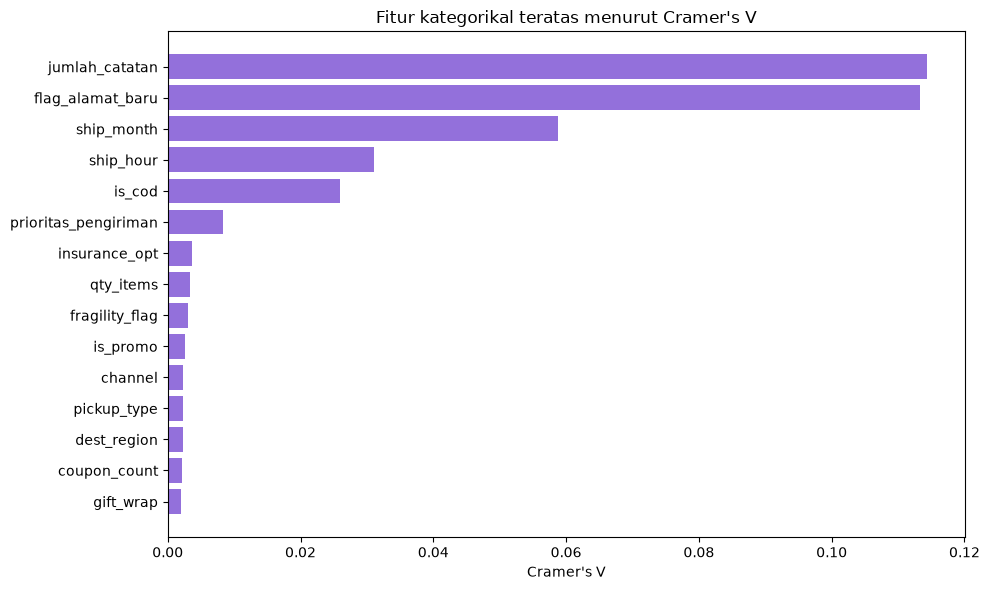

In [48]:
fitur_tampil = ["is_cod", "flag_alamat_baru", "is_promo", "ship_month"]
baris_heatmap, label_heatmap = [], []
status_urut = shipments[TARGET].dropna().unique()
for fitur in fitur_tampil:
    proporsi = pd.crosstab(shipments[fitur], shipments[TARGET], normalize="index")
    for nilai, row in proporsi.iterrows():
        label_heatmap.append(f"{fitur} = {nilai}")
        baris_heatmap.append(row.reindex(status_urut, fill_value=0))
heatmap = pd.DataFrame(baris_heatmap, index=label_heatmap)
fig, ax = plt.subplots(figsize=(13, 9))
im = ax.imshow(heatmap.values * 100, aspect="auto", cmap="YlGnBu", vmin=0, vmax=60)
ax.set_yticks(range(len(heatmap.index)), heatmap.index)
ax.set_xticks(range(len(heatmap.columns)), heatmap.columns, rotation=35, ha="right")
ax.set_title("Komposisi status menurut kategori terpilih")
ax.set_xlabel("Status penanganan")
ax.set_ylabel("Fitur dan level kategori")
fig.colorbar(im, ax=ax, label="Dalam kategori (%)", fraction=0.035, pad=0.02)
fig.tight_layout()
plt.show()


## 6. Shipments: pendalaman fitur kunci

In [49]:
shipments["off_hours"] = ((shipments.ship_hour < 6) | (shipments.ship_hour >= 20)).astype("int8")
shipments["has_note"] = (shipments.jumlah_catatan > 0).astype("int8")
shipments["peak_month"] = shipments.ship_month.isin([3, 10, 11, 12]).astype("int8")
shipments["log_declared"] = np.log1p(shipments.declared_value)

### 6.1 Jam pengiriman

In [50]:
cat_report(shipments, "ship_hour", urut="index", maks=24)
cat_report(shipments, "off_hours")

,n,gagal_antar_awal,klaim_hilang,konfirmasi_alamat,normal,retur_pengirim,rusak_perjalanan,tertunda_operasional
ship_hour,,,,,,,,
0,"2,496",14.3%,2.0%,28.1%,32.2%,7.9%,3.1%,12.3%
1,"2,896",13.2%,2.5%,26.6%,32.2%,8.6%,4.1%,12.8%
2,"5,290",14.7%,2.4%,28.0%,31.0%,8.1%,3.4%,12.3%
3,"9,339",13.7%,2.2%,27.4%,31.4%,8.3%,4.0%,13.0%
4,"15,564",14.0%,2.4%,28.0%,30.8%,8.3%,3.8%,12.6%
5,"23,907",13.8%,2.5%,27.6%,31.6%,8.2%,3.8%,12.6%
6,"35,583",9.7%,3.1%,21.0%,38.6%,7.2%,5.1%,15.3%
7,"50,009",9.6%,3.1%,21.5%,38.7%,6.9%,5.2%,15.0%
8,"66,621",9.4%,3.1%,21.3%,39.1%,6.9%,5.0%,15.1%


,lift_maks,di_level
status_penanganan,,
gagal_antar_awal,1.47,22
klaim_hilang,1.06,12
konfirmasi_alamat,1.28,0
normal,1.03,8
retur_pengirim,1.22,1
rusak_perjalanan,1.05,7
tertunda_operasional,1.04,19


,n,gagal_antar_awal,klaim_hilang,konfirmasi_alamat,normal,retur_pengirim,rusak_perjalanan,tertunda_operasional
off_hours,,,,,,,,
0,"1,124,571",9.6%,3.1%,21.3%,38.8%,6.9%,5.1%,15.2%
1,"119,046",14.0%,2.4%,27.7%,31.2%,8.3%,3.8%,12.7%


,lift_maks,di_level
status_penanganan,,
gagal_antar_awal,1.40,1
klaim_hilang,1.02,0
konfirmasi_alamat,1.26,1
normal,1.02,0
retur_pengirim,1.18,1
rusak_perjalanan,1.03,0
tertunda_operasional,1.02,0


Kesimpulan

Ada ambang tajam di jam 6 dan jam 20, dan di dalam tiap jendela nilainya datar. Pada jam 6 sampai 19: gagal_antar_awal 9,6%, konfirmasi_alamat 21,3%, retur_pengirim 6,9%, normal 38,8%. Pada jam 20 sampai 5: 14,0%, 27,7%, 8,3% dan 31,2%. Hanya 9,6% pengiriman jatuh di jendela ini. Jadi jam cukup diwakili satu fitur biner `off_hours`. Efeknya menggeser kelas yang berkaitan dengan sisi pelanggan (gagal, konfirmasi, retur) naik, sedangkan normal, rusak, klaim dan tertunda turun.

### 6.2 Nilai barang dan jarak

In [51]:
bin_report(shipments, "declared_value")
bin_report(shipments, "distance_km")
show(shipments.groupby(TARGET)[["declared_value", "distance_km"]].median().round(0), "Median per kelas")

,n,gagal_antar_awal,klaim_hilang,konfirmasi_alamat,normal,retur_pengirim,rusak_perjalanan,tertunda_operasional
declared_value,,,,,,,,
"(14999.999, 18000.0]","131,086",9.3%,0.4%,20.9%,43.8%,6.8%,4.5%,14.2%
"(18000.0, 29000.0]","123,317",9.7%,0.5%,21.3%,42.4%,6.8%,4.7%,14.6%
"(29000.0, 41000.0]","122,776",9.9%,0.7%,21.7%,40.9%,7.2%,4.9%,14.8%
"(41000.0, 55000.0]","120,846",10.0%,0.9%,22.0%,39.8%,7.3%,5.1%,15.0%
"(55000.0, 73000.0]","125,320",10.1%,1.2%,22.0%,39.1%,7.5%,5.1%,15.1%
"(73000.0, 97000.0]","126,588",10.3%,1.7%,22.2%,38.0%,7.4%,5.2%,15.3%
"(97000.0, 130000.0]","120,880",10.4%,2.4%,22.4%,37.1%,7.4%,5.1%,15.3%
"(130000.0, 185000.0]","125,448",10.6%,3.6%,22.4%,35.8%,7.3%,5.1%,15.2%
"(185000.0, 300000.0]","123,176",10.3%,5.7%,22.6%,34.0%,6.9%,5.2%,15.3%


,lift_maks,di_level
status_penanganan,,
gagal_antar_awal,1.06,"(130000.0, 185000.0]"
klaim_hilang,4.37,"(300000.0, 13365000.0]"
konfirmasi_alamat,1.03,"(185000.0, 300000.0]"
normal,1.15,"(14999.999, 18000.0]"
retur_pengirim,1.06,"(55000.0, 73000.0]"
rusak_perjalanan,1.04,"(185000.0, 300000.0]"
tertunda_operasional,1.03,"(185000.0, 300000.0]"


,n,gagal_antar_awal,klaim_hilang,konfirmasi_alamat,normal,retur_pengirim,rusak_perjalanan,tertunda_operasional
distance_km,,,,,,,,
"(0.799, 348.7]","124,409",10.6%,3.1%,21.1%,47.3%,6.7%,0.6%,10.7%
"(348.7, 507.9]","124,324",11.2%,3.2%,22.0%,43.4%,7.1%,1.1%,12.0%
"(507.9, 641.9]","124,421",10.9%,3.3%,22.3%,41.1%,7.3%,1.9%,13.3%
"(641.9, 765.7]","124,327",10.9%,3.2%,22.1%,39.8%,7.3%,2.8%,13.9%
"(765.7, 885.8]","124,418",10.5%,3.1%,22.3%,38.4%,7.3%,3.9%,14.5%
"(885.8, 1007.1]","124,328",10.2%,3.0%,22.3%,37.0%,7.2%,4.9%,15.4%
"(1007.1, 1134.1]","124,374",9.8%,2.9%,22.3%,35.6%,7.2%,6.2%,16.0%
"(1134.1, 1275.3]","124,355",9.2%,3.0%,22.0%,34.3%,7.0%,7.6%,16.9%
"(1275.3, 1450.1]","124,336",8.8%,2.8%,21.8%,32.8%,6.8%,9.3%,17.7%


,lift_maks,di_level
status_penanganan,,
gagal_antar_awal,1.12,"(348.7, 507.9]"
klaim_hilang,1.08,"(507.9, 641.9]"
konfirmasi_alamat,1.02,"(765.7, 885.8]"
normal,1.24,"(0.799, 348.7]"
retur_pengirim,1.04,"(507.9, 641.9]"
rusak_perjalanan,2.33,"(1450.1, 1890.6]"
tertunda_operasional,1.27,"(1450.1, 1890.6]"


,declared_value,distance_km
status_penanganan,,
gagal_antar_awal,75000.0,838.0
klaim_hilang,257000.0,855.0
konfirmasi_alamat,75000.0,886.0
normal,66000.0,824.0
retur_pengirim,72000.0,880.0
rusak_perjalanan,75000.0,1202.0
tertunda_operasional,75000.0,966.0


Kesimpulan

`declared_value` menggerakkan klaim_hilang secara monoton: 0,42% di desil terendah naik ke 13,24% di desil tertinggi (lift 4,37), dengan kenaikan makin curam di ujung atas. Ini bukan ambang dan bukan efek outlier. Meski begitu, bahkan di desil teratas hanya 13% yang berakhir klaim, jadi nilai barang saja tidak cukup.

`distance_km` menggerakkan rusak_perjalanan hampir linear: 0,56% di desil terdekat sampai 11,63% di desil terjauh (lift 2,33). tertunda_operasional ikut naik dari 10,7% ke 18,9% dan normal turun dari 47% ke 31%. Sinyal rusak dari jarak ternyata kuat, bukan lemah seperti dugaan awal.

### 6.3 Sinyal alamat

In [52]:
show(pd.crosstab([shipments.has_note, shipments.flag_alamat_baru], shipments[TARGET], normalize="index").round(3),
     "has_note dan flag_alamat_baru")

Kesimpulan

Proporsi konfirmasi_alamat: 11,7% tanpa keduanya, 19,8% hanya flag, 33,1% hanya catatan, 46,5% dengan keduanya. Dalam log-odds efeknya +0,62 dan +1,32, jumlahnya 1,94 hampir sama dengan efek gabungan 1,88, jadi dua sinyal ini saling menambah tanpa interaksi berarti dan model tidak perlu fitur gabungan. Puncaknya hanya 46,5%, sehingga sinyal alamat dari tabel lain (misalnya `address_quality` pelanggan) masih perlu dicari.

### 6.4 Fitur turunan yang tidak berguna

In [53]:
cek = pd.DataFrame({
    "same_city": (shipments.kota_asal == shipments.kota_tujuan).astype("int8"),
    "order_gt24": (shipments.order_to_ship_hours > 24).astype("int8"),
    TARGET: shipments[TARGET],
})
cat_report(cek, "same_city")
cat_report(cek, "order_gt24")
vol_ratio = shipments.berat_volumetrik / shipments.weight_kg
show(vol_ratio.groupby(shipments[TARGET]).describe().round(3), "berat_volumetrik / weight_kg")

,n,gagal_antar_awal,klaim_hilang,konfirmasi_alamat,normal,retur_pengirim,rusak_perjalanan,tertunda_operasional
same_city,,,,,,,,
0,"1,215,296",10.0%,3.0%,21.9%,38.1%,7.1%,5.0%,14.9%
1,"28,321",10.1%,3.0%,22.2%,37.9%,6.9%,4.8%,15.1%


,lift_maks,di_level
status_penanganan,,
gagal_antar_awal,1.01,1
klaim_hilang,1.00,0
konfirmasi_alamat,1.01,1
normal,1.00,0
retur_pengirim,1.00,0
rusak_perjalanan,1.00,0
tertunda_operasional,1.01,1


,n,gagal_antar_awal,klaim_hilang,konfirmasi_alamat,normal,retur_pengirim,rusak_perjalanan,tertunda_operasional
order_gt24,,,,,,,,
0,"1,225,007",10.0%,3.0%,21.9%,38.1%,7.1%,5.0%,14.9%
1,"18,610",10.0%,2.9%,21.9%,37.1%,6.9%,4.9%,16.3%


,lift_maks,di_level
status_penanganan,,
gagal_antar_awal,1.00,1
klaim_hilang,1.00,0
konfirmasi_alamat,1.00,0
normal,1.00,0
retur_pengirim,1.00,0
rusak_perjalanan,1.00,0
tertunda_operasional,1.09,1


,count,mean,std,min,25%,50%,75%,max
status_penanganan,,,,,,,,
gagal_antar_awal,124341.0,2.100,0.578,1.093,1.598,2.103,2.600,3.105
klaim_hilang,37656.0,2.102,0.576,1.094,1.606,2.110,2.600,3.111
konfirmasi_alamat,272911.0,2.098,0.578,1.091,1.597,2.097,2.600,3.115
normal,473531.0,2.101,0.577,1.091,1.602,2.102,2.600,3.111
retur_pengirim,87740.0,2.099,0.576,1.097,1.600,2.100,2.597,3.108
rusak_perjalanan,61942.0,2.100,0.577,1.096,1.601,2.097,2.601,3.105
tertunda_operasional,185496.0,2.100,0.577,1.091,1.601,2.101,2.598,3.111


Kesimpulan

`same_city` tidak membedakan kelas (V 0,002). `order_gt24` hanya sedikit menaikkan tertunda_operasional (16,3% vs 14,9%). Rasio `berat_volumetrik / weight_kg` berdistribusi sama di semua kelas, jadi `berat_volumetrik` tidak menambah informasi di luar `weight_kg`. Ketiganya tidak dipakai.

### Visualisasi Section 6: Pendalaman fitur kunci

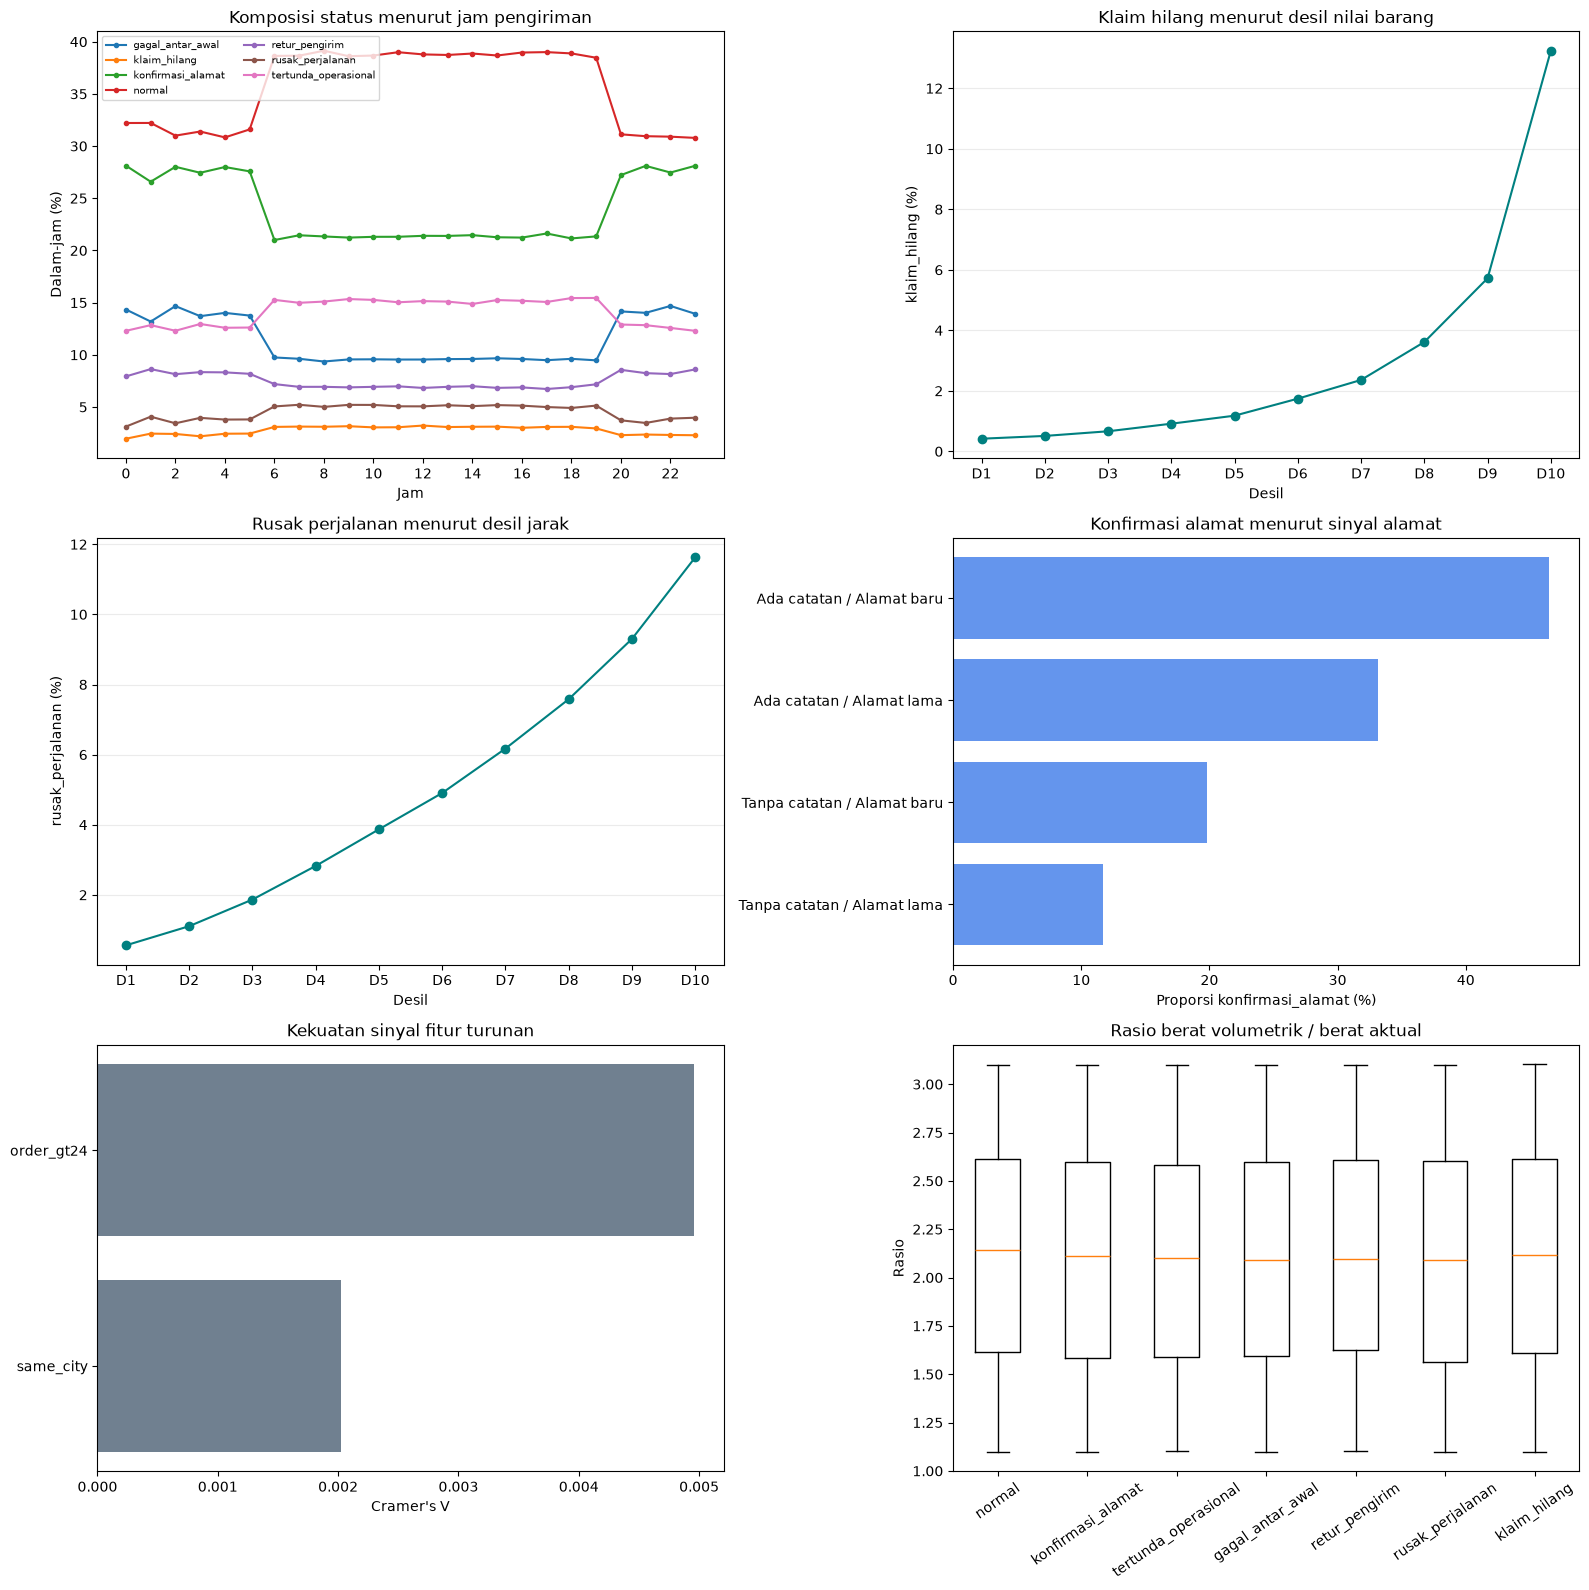

In [54]:
fig, axes = plt.subplots(3, 2, figsize=(16, 16))
jam_status = pd.crosstab(shipments["ship_hour"], shipments[TARGET], normalize="index").reindex(range(24))
for status in jam_status.columns:
    axes[0, 0].plot(jam_status.index, jam_status[status] * 100, marker=".", label=status)
axes[0, 0].set_title("Komposisi status menurut jam pengiriman")
axes[0, 0].set_xlabel("Jam")
axes[0, 0].set_ylabel("Dalam-jam (%)")
axes[0, 0].set_xticks(range(0, 24, 2))
axes[0, 0].legend(fontsize=7, ncol=2)

for ax, kolom, kelas, judul in [
    (axes[0, 1], "declared_value", "klaim_hilang", "Klaim hilang menurut desil nilai barang"),
    (axes[1, 0], "distance_km", "rusak_perjalanan", "Rusak perjalanan menurut desil jarak"),
]:
    bins = pd.qcut(shipments[kolom], q=10, duplicates="drop")
    proporsi = shipments.assign(_bin=bins).groupby("_bin", observed=True)[TARGET].apply(
        lambda s: s.eq(kelas).mean() * 100
    )
    ax.plot(range(len(proporsi)), proporsi.values, marker="o", color="teal")
    ax.set_xticks(range(len(proporsi)))
    ax.set_xticklabels([f"D{i + 1}" for i in range(len(proporsi))])
    ax.set_title(judul)
    ax.set_xlabel("Desil")
    ax.set_ylabel(f"{kelas} (%)")
    ax.grid(axis="y", alpha=0.25)

alamat = shipments.assign(
    _kombinasi=shipments["has_note"].map({0: "Tanpa catatan", 1: "Ada catatan"})
    + " / " + shipments["flag_alamat_baru"].map({0: "Alamat lama", 1: "Alamat baru"})
)
alamat_status = pd.crosstab(alamat["_kombinasi"], alamat[TARGET], normalize="index") * 100
im = axes[1, 1].imshow(alamat_status.values, aspect="auto", cmap="YlOrRd", vmin=0)
axes[1, 1].set_yticks(range(len(alamat_status.index)), alamat_status.index)
axes[1, 1].set_xticks(range(len(alamat_status.columns)), alamat_status.columns, rotation=45, ha="right")
axes[1, 1].set_title("Komposisi status menurut sinyal alamat")
for row in range(alamat_status.shape[0]):
    for col in range(alamat_status.shape[1]):
        value = alamat_status.iloc[row, col]
        axes[1, 1].text(col, row, f"{value:.0f}", ha="center", va="center", fontsize=7,
                        color="white" if value > alamat_status.values.max() * 0.55 else "black")

# Titik menonjolkan bahwa kedua nilai Cramer's V sangat kecil.
turunan_v = pd.Series({
    "same_city": cramers_v(cek["same_city"], cek[TARGET]),
    "order_gt24": cramers_v(cek["order_gt24"], cek[TARGET]),
}).sort_values()
y = np.arange(len(turunan_v))
axes[2, 0].hlines(y, 0, turunan_v.values, color="silver", linewidth=2)
axes[2, 0].scatter(turunan_v.values, y, color="slategray", s=60, zorder=3)
axes[2, 0].set_yticks(y, turunan_v.index)
axes[2, 0].set_title("Kekuatan sinyal fitur turunan")
axes[2, 0].set_xlabel("Cramer's V")
axes[2, 0].grid(axis="x", alpha=0.25)

rasio_plot = (shipments["berat_volumetrik"] / shipments["weight_kg"]).replace([np.inf, -np.inf], np.nan)
kelas_urut = shipments[TARGET].value_counts().index.tolist()
data_box = [
    rasio_plot.loc[shipments[TARGET].eq(kelas)].dropna().sample(
        n=min(2500, rasio_plot.loc[shipments[TARGET].eq(kelas)].notna().sum()), random_state=42
    ).values
    for kelas in kelas_urut
]
axes[2, 1].boxplot(data_box, tick_labels=kelas_urut, showfliers=False)
axes[2, 1].set_title("Rasio berat volumetrik / berat aktual")
axes[2, 1].set_ylabel("Rasio")
axes[2, 1].tick_params(axis="x", labelrotation=35)
fig.tight_layout()
plt.show()


## 7. Tabel anak: scan, rute, invoice

### 7.1 Agregasi per pengiriman

In [55]:
idx = pd.Index(shipments.shipment_id)
for d in (event, route, invoices):
    d["sid"] = idx.get_indexer(d.shipment_id).astype("int32")
    print(len(d), "baris tanpa induk:", (d.sid < 0).sum())

6837111 baris tanpa induk: 0
2200148 baris tanpa induk: 0
1467722 baris tanpa induk: 0


In [56]:
g = event.groupby("sid")
ev = g.agg(n_scan=("gap_hours", "size"), gap_sum=("gap_hours", "sum"),
           gap_mean=("gap_hours", "mean"), gap_max=("gap_hours", "max"),
           manual_ratio=("is_manual", "mean"), q_mean=("scan_quality", "mean"),
           q_min=("scan_quality", "min"),
           first_event=("event_type", "first"), last_event=("event_type", "last"))
ev_cnt = (event.groupby(["sid", "event_type"], observed=True).size()
          .unstack(fill_value=0).add_prefix("ev_"))
ev = ev.join(ev_cnt)

route["dur_kosong"] = route.durasi_jam.isna().astype("int8")
rt = route.groupby("sid").agg(n_seg=("urutan", "size"), jarak_seg=("jarak_segmen_km", "sum"),
                              durasi_seg=("durasi_jam", "sum"), dur_kosong=("dur_kosong", "sum"),
                              biaya_seg=("biaya_segmen", "sum"), n_hub_seg=("segmen_hub_id", "nunique"))
rt["kecepatan"] = rt.jarak_seg / rt.durasi_seg.replace(0, np.nan)
moda = route.groupby(["sid", "moda"]).size().unstack(fill_value=0).add_prefix("moda_")
rt = rt.join(moda)
rt["n_moda"] = (moda > 0).sum(axis=1)

invoices["tertunda"] = (invoices.payment_status == "tertunda").astype("int8")
inv = invoices.groupby("sid").agg(n_inv=("amount", "size"), inv_total=("amount", "sum"),
                                  penalti=("is_penalty", "max"), inv_tertunda=("tertunda", "sum"),
                                  hari_bayar_maks=("days_to_pay", "max"),
                                  bulan_inv_maks=("issued_month", "max"))
jenis = invoices.groupby(["sid", "invoice_type"]).size().unstack(fill_value=0).add_prefix("inv_")
inv = inv.join(jenis)

df = shipments.join(ev).join(rt).join(inv).copy()

In [57]:
show((100 * df[["n_scan", "n_seg", "n_inv"]].isna().groupby(df[TARGET]).mean()).round(2),
     "Pengiriman tanpa baris di tabel anak (%) per kelas")
hitung = (["n_scan", "n_seg", "n_inv", "inv_total", "inv_tertunda", "penalti", "n_moda"]
          + list(ev_cnt.columns) + list(moda.columns) + list(jenis.columns))
df[hitung] = df[hitung].fillna(0)

,n_scan,n_seg,n_inv
status_penanganan,,,
gagal_antar_awal,0.0,0.0,0.0
klaim_hilang,0.0,0.0,0.0
konfirmasi_alamat,0.0,0.0,0.0
normal,0.0,0.0,0.0
retur_pengirim,0.0,0.0,0.0
rusak_perjalanan,0.0,0.0,0.0
tertunda_operasional,0.0,0.0,0.0


### 7.2 Scan events

In [58]:
df["n_upaya"] = df.ev_upaya_antar.clip(upper=6)
df["n_pickup"] = df.ev_pickup.clip(upper=5)
df["ada_selesai"] = (df.ev_selesai > 0).astype("int8")
for c in ["last_event", "first_event", "ada_selesai", "n_upaya", "n_pickup", "n_scan"]:
    cat_report(df, c, urut="index", maks=20)

,n,gagal_antar_awal,klaim_hilang,konfirmasi_alamat,normal,retur_pengirim,rusak_perjalanan,tertunda_operasional
last_event,,,,,,,,
keluar_hub,0,nan%,nan%,nan%,nan%,nan%,nan%,nan%
pickup,0,nan%,nan%,nan%,nan%,nan%,nan%,nan%
selesai,"831,294",9.7%,3.2%,19.1%,40.4%,7.0%,5.2%,15.4%
sortasi,0,nan%,nan%,nan%,nan%,nan%,nan%,nan%
transit,0,nan%,nan%,nan%,nan%,nan%,nan%,nan%
upaya_antar,"412,323",10.6%,2.7%,27.7%,33.4%,7.2%,4.5%,13.9%


,lift_maks,di_level
status_penanganan,,
gagal_antar_awal,1.06,upaya_antar
klaim_hilang,1.05,selesai
konfirmasi_alamat,1.26,upaya_antar
normal,1.06,selesai
retur_pengirim,1.02,upaya_antar
rusak_perjalanan,1.05,selesai
tertunda_operasional,1.03,selesai


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_14920\357351150.py:19: RuntimeWarning: invalid value encountered in divide
  return np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))


,n,gagal_antar_awal,klaim_hilang,konfirmasi_alamat,normal,retur_pengirim,rusak_perjalanan,tertunda_operasional
first_event,,,,,,,,
keluar_hub,0,nan%,nan%,nan%,nan%,nan%,nan%,nan%
pickup,"1,243,617",10.0%,3.0%,21.9%,38.1%,7.1%,5.0%,14.9%
selesai,0,nan%,nan%,nan%,nan%,nan%,nan%,nan%
sortasi,0,nan%,nan%,nan%,nan%,nan%,nan%,nan%
transit,0,nan%,nan%,nan%,nan%,nan%,nan%,nan%
upaya_antar,0,nan%,nan%,nan%,nan%,nan%,nan%,nan%


,lift_maks,di_level
status_penanganan,,
gagal_antar_awal,1.0,pickup
klaim_hilang,1.0,pickup
konfirmasi_alamat,1.0,pickup
normal,1.0,pickup
retur_pengirim,1.0,pickup
rusak_perjalanan,1.0,pickup
tertunda_operasional,1.0,pickup


,n,gagal_antar_awal,klaim_hilang,konfirmasi_alamat,normal,retur_pengirim,rusak_perjalanan,tertunda_operasional
ada_selesai,,,,,,,,
0,"412,323",10.6%,2.7%,27.7%,33.4%,7.2%,4.5%,13.9%
1,"831,294",9.7%,3.2%,19.1%,40.4%,7.0%,5.2%,15.4%


... (3 outputs left out)

,n,gagal_antar_awal,klaim_hilang,konfirmasi_alamat,normal,retur_pengirim,rusak_perjalanan,tertunda_operasional
n_pickup,,,,,,,,
1,"694,715",10.1%,3.0%,23.7%,36.7%,7.1%,4.8%,14.7%
2,"403,186",10.0%,3.1%,20.5%,39.2%,7.0%,5.1%,15.1%
3,"118,402",9.6%,3.2%,18.1%,41.2%,7.1%,5.4%,15.4%
4,"23,327",9.5%,3.3%,15.7%,43.3%,6.8%,5.9%,15.5%
5,"3,987",9.3%,3.6%,12.9%,45.9%,6.7%,5.8%,15.7%


,lift_maks,di_level
status_penanganan,,
gagal_antar_awal,1.01,1
klaim_hilang,1.20,5
konfirmasi_alamat,1.08,1
normal,1.21,5
retur_pengirim,1.00,3
rusak_perjalanan,1.18,4
tertunda_operasional,1.05,5


,n,gagal_antar_awal,klaim_hilang,konfirmasi_alamat,normal,retur_pengirim,rusak_perjalanan,tertunda_operasional
n_scan,,,,,,,,
2,"37,589",9.8%,3.0%,22.0%,38.4%,7.2%,4.7%,15.0%
3,"130,881",9.9%,3.0%,21.8%,38.0%,7.0%,5.0%,15.2%
4,"231,486",10.0%,3.0%,21.8%,38.2%,7.0%,5.0%,15.0%
5,"268,491",10.0%,3.0%,21.9%,37.9%,7.1%,4.9%,15.0%
6,"234,480",10.0%,3.0%,22.0%,38.1%,7.0%,4.9%,14.9%
7,"163,986",10.1%,3.1%,22.0%,38.0%,7.1%,5.1%,14.7%
8,"95,463",10.1%,2.9%,22.2%,38.1%,7.0%,5.1%,14.7%
9,"48,122",10.1%,3.1%,21.9%,38.4%,7.0%,5.1%,14.4%
10,"20,911",10.2%,3.1%,21.9%,38.0%,7.4%,5.1%,14.3%


,lift_maks,di_level
status_penanganan,,
gagal_antar_awal,1.04,11
klaim_hilang,1.06,11
konfirmasi_alamat,1.04,12
normal,1.01,9
retur_pengirim,1.05,10
rusak_perjalanan,1.02,10
tertunda_operasional,1.02,3


In [59]:
kol_scan = ["gap_sum", "gap_mean", "gap_max", "manual_ratio", "q_mean", "q_min"]
show(eta_sq(df, kol_scan).round(5).to_frame("eta2"), "Eta kuadrat fitur scan")
show(df.groupby(TARGET)[kol_scan].mean().T.round(2), "Rata-rata per kelas")
bin_report(df, "gap_max")
bin_report(df, "manual_ratio", q=5)

,eta2
gap_mean,0.09914
q_mean,0.09496
gap_sum,0.06656
gap_max,0.06295
q_min,0.05595
manual_ratio,0.02916


status_penanganan,gagal_antar_awal,klaim_hilang,konfirmasi_alamat,normal,retur_pengirim,rusak_perjalanan,tertunda_operasional
gap_sum,44.48,44.57,45.31,41.61,45.06,43.90,62.46
gap_mean,8.07,8.08,8.23,7.56,8.19,7.96,11.40
gap_max,17.23,17.26,17.56,16.15,17.46,17.04,24.27
manual_ratio,0.22,0.18,0.18,0.15,0.19,0.28,0.19
q_mean,3.40,3.63,3.65,3.79,3.59,3.09,3.58
q_min,2.41,2.68,2.71,2.88,2.63,2.08,2.63


,n,gagal_antar_awal,klaim_hilang,konfirmasi_alamat,normal,retur_pengirim,rusak_perjalanan,tertunda_operasional
gap_max,,,,,,,,
"(0.259, 7.37]","124,473",10.2%,3.0%,22.1%,47.5%,6.9%,5.2%,5.0%
"(7.37, 9.6]","124,453",10.4%,3.2%,22.3%,45.1%,7.2%,5.3%,6.6%
"(9.6, 11.54]","124,588",10.3%,3.2%,22.4%,43.3%,7.2%,5.3%,8.2%
"(11.54, 13.45]","124,318",10.6%,3.2%,22.3%,41.4%,7.4%,5.3%,9.8%
"(13.45, 15.5]","124,485",10.5%,3.1%,22.4%,39.8%,7.3%,5.2%,11.7%
"(15.5, 17.82]","124,016",10.4%,3.2%,22.4%,37.7%,7.4%,5.2%,13.8%
"(17.82, 20.68]","124,442",10.3%,3.0%,22.3%,35.9%,7.2%,5.1%,16.3%
"(20.68, 24.61]","124,139",9.7%,3.0%,21.9%,34.0%,7.2%,4.8%,19.4%
"(24.61, 31.36]","124,450",9.4%,2.8%,21.7%,30.8%,6.7%,4.5%,24.1%


,lift_maks,di_level
status_penanganan,,
gagal_antar_awal,1.06,"(11.54, 13.45]"
klaim_hilang,1.07,"(9.6, 11.54]"
konfirmasi_alamat,1.02,"(13.45, 15.5]"
normal,1.25,"(0.259, 7.37]"
retur_pengirim,1.05,"(11.54, 13.45]"
rusak_perjalanan,1.06,"(9.6, 11.54]"
tertunda_operasional,2.30,"(31.36, 221.26]"


,n,gagal_antar_awal,klaim_hilang,konfirmasi_alamat,normal,retur_pengirim,rusak_perjalanan,tertunda_operasional
manual_ratio,,,,,,,,
"(-0.001, 0.0714]","497,490",7.5%,2.9%,22.0%,44.3%,6.6%,2.6%,14.0%
"(0.0714, 0.2]","292,035",10.1%,3.1%,22.4%,37.7%,7.2%,4.4%,15.1%
"(0.2, 0.333]","256,326",11.8%,3.1%,21.9%,33.8%,7.4%,6.3%,15.7%
"(0.333, 1.0]","197,766",13.9%,3.0%,21.1%,28.5%,7.5%,10.0%,16.1%


,lift_maks,di_level
status_penanganan,,
gagal_antar_awal,1.39,"(0.333, 1.0]"
klaim_hilang,1.03,"(0.2, 0.333]"
konfirmasi_alamat,1.02,"(0.0714, 0.2]"
normal,1.16,"(-0.001, 0.0714]"
retur_pengirim,1.06,"(0.333, 1.0]"
rusak_perjalanan,2.00,"(0.333, 1.0]"
tertunda_operasional,1.08,"(0.333, 1.0]"


### 7.3 Rute

In [60]:
df["biaya_per_km"] = df.biaya_seg / df.jarak_seg.replace(0, np.nan)
for c in ["n_seg", "n_moda", "dur_kosong"] + list(moda.columns):
    cat_report(df, c, urut="index")
kol_rute = ["jarak_seg", "durasi_seg", "biaya_seg", "kecepatan", "biaya_per_km"]
show(eta_sq(df, kol_rute).round(5).to_frame("eta2"), "Eta kuadrat fitur rute")
show(df.groupby(TARGET)[kol_rute].mean().T.round(2), "Rata-rata per kelas")
bin_report(df, "kecepatan")

,n,gagal_antar_awal,klaim_hilang,konfirmasi_alamat,normal,retur_pengirim,rusak_perjalanan,tertunda_operasional
n_seg,,,,,,,,
1,"436,937",10.6%,3.2%,22.1%,38.7%,7.2%,2.9%,15.3%
2,"656,829",9.9%,3.0%,21.9%,38.0%,7.1%,5.4%,14.8%
3,"149,851",8.8%,2.8%,21.7%,36.7%,6.6%,9.3%,14.2%


,lift_maks,di_level
status_penanganan,,
gagal_antar_awal,1.06,1
klaim_hilang,1.04,1
konfirmasi_alamat,1.01,1
normal,1.02,1
retur_pengirim,1.02,1
rusak_perjalanan,1.87,3
tertunda_operasional,1.03,1


,n,gagal_antar_awal,klaim_hilang,konfirmasi_alamat,normal,retur_pengirim,rusak_perjalanan,tertunda_operasional
n_moda,,,,,,,,
1,"758,467",10.3%,3.1%,22.1%,38.5%,7.2%,4.2%,14.7%
2,"456,734",9.6%,2.9%,21.8%,37.5%,6.9%,6.0%,15.2%
3,"28,416",8.7%,2.7%,21.6%,36.5%,6.4%,9.1%,15.1%


,lift_maks,di_level
status_penanganan,,
gagal_antar_awal,1.03,1
klaim_hilang,1.02,1
konfirmasi_alamat,1.01,1
normal,1.01,1
retur_pengirim,1.02,1
rusak_perjalanan,1.82,3
tertunda_operasional,1.02,2


,n,gagal_antar_awal,klaim_hilang,konfirmasi_alamat,normal,retur_pengirim,rusak_perjalanan,tertunda_operasional
dur_kosong,,,,,,,,
0,"1,200,092",10.0%,3.0%,21.9%,38.1%,7.1%,5.0%,14.9%
1,"43,085",9.9%,3.1%,21.9%,38.0%,7.2%,5.7%,14.2%
2,437,10.3%,3.2%,18.5%,38.7%,7.3%,5.5%,16.5%
3,3,0.0%,0.0%,33.3%,33.3%,0.0%,0.0%,33.3%


,lift_maks,di_level
status_penanganan,,
gagal_antar_awal,1.00,0
klaim_hilang,1.03,1
konfirmasi_alamat,1.00,0
normal,1.00,0
retur_pengirim,1.02,1
rusak_perjalanan,1.15,1
tertunda_operasional,1.00,0


... (8 outputs left out)

,eta2
durasi_seg,0.06470
jarak_seg,0.03483
kecepatan,0.03380
biaya_seg,0.02561
biaya_per_km,0.00000


status_penanganan,gagal_antar_awal,klaim_hilang,konfirmasi_alamat,normal,retur_pengirim,rusak_perjalanan,tertunda_operasional
jarak_seg,856.23,872.04,893.30,842.30,889.37,1174.44,959.31
durasi_seg,23.04,23.46,24.44,21.82,24.17,31.28,32.90
biaya_seg,1412850.13,1439515.77,1474576.35,1389930.59,1466684.30,1936234.13,1583651.31
kecepatan,42.04,41.98,41.61,43.92,41.53,42.27,33.36
biaya_per_km,1649.59,1650.63,1651.03,1650.33,1649.39,1648.39,1650.42


,n,gagal_antar_awal,klaim_hilang,konfirmasi_alamat,normal,retur_pengirim,rusak_perjalanan,tertunda_operasional
kecepatan,,,,,,,,
"(6.903, 23.998]","123,469",8.2%,2.5%,19.7%,26.6%,6.1%,3.3%,33.6%
"(23.998, 28.293]","123,468",9.2%,2.8%,21.2%,30.7%,6.6%,4.3%,25.1%
"(28.293, 31.65]","123,468",9.8%,2.9%,22.0%,33.0%,7.1%,5.0%,20.2%
"(31.65, 34.745]","123,468",10.1%,3.1%,22.5%,35.2%,7.3%,5.2%,16.6%
"(34.745, 37.893]","123,469",10.3%,3.2%,22.5%,37.6%,7.5%,5.4%,13.5%
"(37.893, 41.372]","123,468",10.7%,3.2%,22.6%,39.4%,7.5%,5.7%,11.0%
"(41.372, 45.526]","123,468",10.6%,3.1%,22.5%,41.5%,7.3%,5.6%,9.4%
"(45.526, 51.214]","123,468",10.4%,3.2%,22.4%,43.4%,7.2%,5.5%,7.9%
"(51.214, 61.151]","123,468",10.3%,3.1%,22.2%,45.4%,7.0%,5.2%,6.8%


,lift_maks,di_level
status_penanganan,,
gagal_antar_awal,1.07,"(37.893, 41.372]"
klaim_hilang,1.07,"(34.745, 37.893]"
konfirmasi_alamat,1.03,"(37.893, 41.372]"
normal,1.26,"(61.151, 852.156]"
retur_pengirim,1.06,"(37.893, 41.372]"
rusak_perjalanan,1.14,"(37.893, 41.372]"
tertunda_operasional,2.25,"(6.903, 23.998]"


### 7.4 Invoice

In [61]:
show(pd.crosstab(invoices.invoice_type, invoices.discount.isna()), "invoice_type vs discount kosong")
df["lag_bulan_inv"] = (df.bulan_inv_maks - df.ship_month) % 12
for c in list(jenis.columns) + ["penalti", "inv_tertunda", "n_inv", "lag_bulan_inv"]:
    cat_report(df, c, urut="index")
kol_inv = ["inv_total", "hari_bayar_maks"]
show(eta_sq(df, kol_inv).round(5).to_frame("eta2"), "Eta kuadrat fitur invoice")
bin_report(df, "hari_bayar_maks", q=5)

discount,False,True
invoice_type,,
klaim,224105,0
langganan,0,622355
pengiriman,621262,0


,n,gagal_antar_awal,klaim_hilang,konfirmasi_alamat,normal,retur_pengirim,rusak_perjalanan,tertunda_operasional
inv_klaim,,,,,,,,
0,"1,019,512",10.4%,2.5%,22.4%,38.9%,5.4%,5.2%,15.2%
1,"224,105",8.3%,5.4%,19.7%,34.4%,14.6%,4.2%,13.4%


,lift_maks,di_level
status_penanganan,,
gagal_antar_awal,1.04,0
klaim_hilang,1.80,1
konfirmasi_alamat,1.02,0
normal,1.02,0
retur_pengirim,2.07,1
rusak_perjalanan,1.03,0
tertunda_operasional,1.02,0


,n,gagal_antar_awal,klaim_hilang,konfirmasi_alamat,normal,retur_pengirim,rusak_perjalanan,tertunda_operasional
inv_langganan,,,,,,,,
0,"621,262",10.0%,3.0%,21.9%,38.1%,7.1%,5.0%,14.9%
1,"622,355",10.0%,3.1%,22.0%,38.1%,7.0%,5.0%,14.9%


,lift_maks,di_level
status_penanganan,,
gagal_antar_awal,1.00,1
klaim_hilang,1.01,1
konfirmasi_alamat,1.00,1
normal,1.00,0
retur_pengirim,1.00,0
rusak_perjalanan,1.00,0
tertunda_operasional,1.00,0


,n,gagal_antar_awal,klaim_hilang,konfirmasi_alamat,normal,retur_pengirim,rusak_perjalanan,tertunda_operasional
inv_pengiriman,,,,,,,,
0,"622,355",10.0%,3.1%,22.0%,38.1%,7.0%,5.0%,14.9%
1,"621,262",10.0%,3.0%,21.9%,38.1%,7.1%,5.0%,14.9%


... (8 outputs left out)

,lift_maks,di_level
status_penanganan,,
gagal_antar_awal,1.03,0
klaim_hilang,1.81,1
konfirmasi_alamat,1.02,0
normal,1.02,0
retur_pengirim,2.07,1
rusak_perjalanan,1.03,0
tertunda_operasional,1.03,0


,eta2
inv_total,0.03966
hari_bayar_maks,0.02543


,n,gagal_antar_awal,klaim_hilang,konfirmasi_alamat,normal,retur_pengirim,rusak_perjalanan,tertunda_operasional
hari_bayar_maks,,,,,,,,
"(-0.001, 2.0]","417,494",9.4%,2.5%,21.1%,44.1%,5.4%,4.6%,12.9%
"(2.0, 3.0]","190,198",9.8%,2.9%,21.9%,40.5%,6.6%,4.9%,13.5%
"(3.0, 4.0]","155,233",10.2%,3.2%,22.1%,38.3%,7.3%,5.0%,13.9%
"(4.0, 7.0]","280,730",10.6%,3.4%,22.8%,35.0%,8.2%,5.3%,14.7%
"(7.0, 45.0]","199,962",10.5%,3.6%,22.4%,27.2%,9.2%,5.4%,21.6%


,lift_maks,di_level
status_penanganan,,
gagal_antar_awal,1.06,"(4.0, 7.0]"
klaim_hilang,1.19,"(7.0, 45.0]"
konfirmasi_alamat,1.04,"(4.0, 7.0]"
normal,1.16,"(-0.001, 2.0]"
retur_pengirim,1.30,"(7.0, 45.0]"
rusak_perjalanan,1.09,"(7.0, 45.0]"
tertunda_operasional,1.45,"(7.0, 45.0]"


### 7.5 Pengecekan struktur data

In [62]:
ada = event.sid.values >= 0
hub_ship = shipments.hub_id.to_numpy()[event.sid.values[ada]]
print("hub di scan sama dengan hub shipment:", (event.hub_id.to_numpy()[ada] == hub_ship).mean())
print("pengiriman dengan lebih dari 1 hub di rute:", (rt.n_hub_seg > 1).mean())

d = (df.jarak_seg - df.distance_km).dropna()
print("selisih jarak rute dan distance_km:")
print(d.abs().describe().round(3))
show((d.abs() > 0.5).groupby(df[TARGET]).mean().round(4).to_frame("selisih > 0,5 km"))

pos = event.groupby("sid").cumcount()
tot = event.sid.map(ev.n_scan)
print("scan selesai yang bukan scan terakhir:", ((event.event_type == "selesai") & (pos < tot - 1)).sum())
print(df.first_event.value_counts(normalize=True).round(3))

hub di scan sama dengan hub shipment: 1.0
pengiriman dengan lebih dari 1 hub di rute: 0.0
selisih jarak rute dan distance_km:
count    1243617.000
mean           0.003
std            0.017
min            0.000
25%            0.000
50%            0.000
75%            0.000
max            0.100
dtype: float64


,"selisih > 0,5 km"
status_penanganan,
gagal_antar_awal,0.0
klaim_hilang,0.0
konfirmasi_alamat,0.0
normal,0.0
retur_pengirim,0.0
rusak_perjalanan,0.0
tertunda_operasional,0.0


scan selesai yang bukan scan terakhir: 0
first_event
pickup         1.0
keluar_hub     0.0
selesai        0.0
sortasi        0.0
transit        0.0
upaya_antar    0.0
Name: proportion, dtype: float64


In [63]:
ringkas(["last_event", "first_event", "ada_selesai", "n_upaya", "n_pickup", "n_scan", "gap_max", "gap_mean",
         "manual_ratio", "q_mean", "n_seg", "n_moda", "kecepatan", "biaya_per_km"] +
        list(jenis.columns) + ["penalti", "inv_tertunda", "n_inv", "lag_bulan_inv", "hari_bayar_maks"])

,fitur,kelas,lift_maks,lift_min,rasio
0,q_mean,gagal_antar_awal,1.65,0.34,4.80
1,manual_ratio,gagal_antar_awal,1.43,0.75,1.91
2,gap_mean,gagal_antar_awal,1.07,0.76,1.41
3,n_inv,klaim_hilang,1.80,0.82,2.18
4,inv_klaim,klaim_hilang,1.80,0.82,2.18
5,lag_bulan_inv,klaim_hilang,1.81,0.84,2.15
6,n_upaya,konfirmasi_alamat,2.33,0.62,3.73
7,n_pickup,konfirmasi_alamat,1.08,0.72,1.50
8,ada_selesai,konfirmasi_alamat,1.26,0.87,1.45
9,q_mean,normal,1.48,0.59,2.51


Kesimpulan

Yang perlu dijawab:
- (a) kelas mana yang tidak punya scan selesai dan berapa upaya antarnya;
- (b) apakah invoice klaim dan penalti terkait klaim_hilang atau rusak_perjalanan;
- (c) apakah hub di scan dan rute selalu sama dengan hub shipment;
- (d) apakah jarak rute selalu sama dengan distance_km;
- (e) apakah urutan baris scan benar-benar kronologis.

## 8. Tabel master: kurir, pelanggan, hub, layanan, promo

In [64]:
master = [(courier, "courier_id", "kr_"), (custom, "customer_id", "cu_"), (hubs, "hub_id", "hb_"),
          (service, "package_id", "sv_"), (promo, "promo_id", "pr_")]
for tabel, kunci, pref in master:
    print(pref, "kunci ganda:", tabel[kunci].duplicated().sum())
    t = tabel.set_index(kunci).add_prefix(pref)
    df = df.drop(columns=t.columns, errors="ignore").join(t, on=kunci)
df = df.copy()
print(len(df), len(shipments))
show(df[["kr_vehicle_type", "cu_segment", "hb_hub_type", "sv_speed_class", "pr_tipe_promo"]]
     .isna().mean().round(4).to_frame("kosong"), "Hasil join ke tabel master")

kr_ kunci ganda: 0
cu_ kunci ganda: 0
hb_ kunci ganda: 0
sv_ kunci ganda: 0
pr_ kunci ganda: 0
1243617 1243617


,kosong
kr_vehicle_type,0.0000
cu_segment,0.0000
hb_hub_type,0.0000
sv_speed_class,0.0000
pr_tipe_promo,0.8302


In [65]:
kat_master = ["kr_vehicle_type", "kr_contract_type", "kr_shift_code", "kr_training_level",
              "kr_sertifikasi_hazardous", "cu_region", "cu_segment", "cu_is_business", "cu_preferred_payment",
              "cu_loyalty_tier", "cu_address_quality", "cu_is_verified", "cu_kota_tipe",
              "cu_metode_notifikasi", "cu_tagihan_langganan", "hb_region", "hb_hub_type",
              "hb_automation_level", "sv_speed_class", "sv_handling_class", "sv_insurance_default",
              "sv_cod_allowed", "pr_tipe_promo", "pr_nama_promo"]
vm = pd.Series({c: cramers_v(df[c], df[TARGET]) for c in kat_master}).sort_values(ascending=False)
show(vm.round(4).to_frame("cramers_v"))
for c in vm.index[:6]:
    cat_report(df, c, maks=10)

,cramers_v
cu_address_quality,0.2981
hb_automation_level,0.1121
sv_speed_class,0.0337
hb_hub_type,0.0296
hb_region,0.0270
cu_preferred_payment,0.0232
pr_nama_promo,0.0089
kr_training_level,0.0086
kr_vehicle_type,0.0060
kr_shift_code,0.0057


,n,gagal_antar_awal,klaim_hilang,konfirmasi_alamat,normal,retur_pengirim,rusak_perjalanan,tertunda_operasional
cu_address_quality,,,,,,,,
3,"380,806",13.8%,3.1%,16.9%,36.5%,8.7%,5.0%,15.9%
4,"316,477",9.0%,4.0%,3.7%,50.9%,7.4%,6.8%,18.2%
2,"250,823",12.3%,1.8%,44.4%,20.0%,7.4%,2.8%,11.3%
5,"185,965",3.3%,4.2%,0.6%,62.6%,4.4%,7.1%,17.7%
1,"109,546",5.5%,0.8%,76.9%,6.3%,3.9%,1.0%,5.6%


,lift_maks,di_level
status_penanganan,,
gagal_antar_awal,1.38,3
klaim_hilang,1.39,5
konfirmasi_alamat,3.50,1
normal,1.64,5
retur_pengirim,1.23,3
rusak_perjalanan,1.43,5
tertunda_operasional,1.22,4


,n,gagal_antar_awal,klaim_hilang,konfirmasi_alamat,normal,retur_pengirim,rusak_perjalanan,tertunda_operasional
hb_automation_level,,,,,,,,
3,"476,134",10.2%,2.0%,22.1%,38.3%,7.2%,5.1%,15.1%
2,"318,200",10.9%,4.7%,23.5%,30.6%,8.0%,5.5%,16.9%
4,"282,267",8.8%,0.9%,20.2%,46.6%,6.2%,4.4%,12.9%
1,"84,516",11.7%,12.2%,24.3%,21.5%,7.8%,6.1%,16.5%
5,"82,500",7.5%,0.4%,18.5%,53.3%,4.9%,3.4%,11.9%


,lift_maks,di_level
status_penanganan,,
gagal_antar_awal,1.17,1
klaim_hilang,4.03,1
konfirmasi_alamat,1.11,1
normal,1.40,5
retur_pengirim,1.13,2
rusak_perjalanan,1.22,1
tertunda_operasional,1.13,2


,n,gagal_antar_awal,klaim_hilang,konfirmasi_alamat,normal,retur_pengirim,rusak_perjalanan,tertunda_operasional
sv_speed_class,,,,,,,,
reguler,"661,563",10.0%,3.0%,22.0%,38.6%,7.1%,5.1%,14.3%
express,"381,018",10.0%,3.0%,21.8%,39.1%,7.0%,4.9%,14.2%
same_day,"201,036",10.1%,3.0%,22.0%,34.5%,7.1%,5.0%,18.4%


... (3 outputs left out)

,n,gagal_antar_awal,klaim_hilang,konfirmasi_alamat,normal,retur_pengirim,rusak_perjalanan,tertunda_operasional
hb_region,,,,,,,,
bali_nusa,"200,915",10.1%,3.2%,22.1%,38.8%,7.1%,5.0%,13.8%
kalimantan,"195,019",9.8%,2.9%,22.0%,38.0%,7.1%,4.9%,15.4%
jawa_tengah,"186,375",10.7%,3.9%,22.5%,36.2%,7.4%,5.4%,13.8%
jawa_barat,"174,064",9.7%,3.2%,21.9%,36.5%,7.0%,4.8%,16.9%
sulawesi,"170,952",9.8%,2.9%,22.0%,38.5%,7.0%,4.9%,14.8%
sumatera,"160,501",10.0%,2.6%,22.0%,41.8%,7.0%,5.0%,11.6%
jawa_timur,"155,791",9.8%,2.4%,21.0%,36.9%,6.7%,4.9%,18.4%


,lift_maks,di_level
status_penanganan,,
gagal_antar_awal,1.07,jawa_tengah
klaim_hilang,1.28,jawa_tengah
konfirmasi_alamat,1.03,jawa_tengah
normal,1.10,sumatera
retur_pengirim,1.05,jawa_tengah
rusak_perjalanan,1.08,jawa_tengah
tertunda_operasional,1.23,jawa_timur


,n,gagal_antar_awal,klaim_hilang,konfirmasi_alamat,normal,retur_pengirim,rusak_perjalanan,tertunda_operasional
cu_preferred_payment,,,,,,,,
transfer,"472,704",10.1%,3.1%,22.0%,38.3%,6.6%,5.0%,15.0%
ewallet,"372,128",10.1%,3.0%,22.1%,38.1%,6.7%,5.0%,15.0%
kartu,"212,344",10.0%,3.1%,22.0%,38.4%,6.5%,5.1%,15.0%
cod,"186,441",9.6%,2.8%,21.5%,37.2%,9.5%,4.9%,14.6%


,lift_maks,di_level
status_penanganan,,
gagal_antar_awal,1.01,ewallet
klaim_hilang,1.02,transfer
konfirmasi_alamat,1.01,ewallet
normal,1.01,kartu
retur_pengirim,1.34,cod
rusak_perjalanan,1.02,kartu
tertunda_operasional,1.01,ewallet


In [66]:
num_master = ["kr_experience_years", "kr_courier_score", "kr_jarak_domisili_hub_km", "kr_kapasitas_muatan_kg",
              "cu_tenure_months", "cu_credit_score", "cu_complaint_index", "hb_capacity_index",
              "hb_density_index", "hb_luas_gudang_m2", "sv_cost_multiplier", "sv_max_weight_kg",
              "sv_fragile_score", "sv_estimasi_hari", "sv_biaya_dasar", "pr_diskon_persen"]
show(eta_sq(df, num_master).round(5).to_frame("eta2"), "Eta kuadrat fitur master numerik")

,eta2
cu_complaint_index,0.29679
hb_density_index,0.12846
kr_courier_score,0.11970
hb_capacity_index,0.11099
cu_credit_score,0.06331
kr_experience_years,0.04687
sv_fragile_score,0.00212
hb_luas_gudang_m2,0.00037
sv_estimasi_hari,0.00014
sv_biaya_dasar,0.00014


In [67]:
df["lewat_kapasitas"] = (df.weight_kg > df.kr_kapasitas_muatan_kg).astype("int8")
df["lewat_batas_paket"] = (df.weight_kg > df.sv_max_weight_kg).astype("int8")
df["cod_dilarang"] = ((df.is_cod == 1) & (df.sv_cod_allowed == 0)).astype("int8")
df["beda_hub_kurir"] = (df.hub_id != df.kr_hub_id).astype("int8")
df["luar_jam_hub"] = ((df.ship_hour < df.hb_jam_buka) | (df.ship_hour >= df.hb_jam_tutup)).astype("int8")

a, b, bln = df.pr_bulan_mulai, df.pr_bulan_akhir, df.ship_month
dalam = np.where(a <= b, (bln >= a) & (bln <= b), (bln >= a) | (bln <= b))
df["promo_aktif"] = np.where(a.isna(), -1, dalam).astype("int8")

for c in ["lewat_kapasitas", "lewat_batas_paket", "cod_dilarang", "beda_hub_kurir", "luar_jam_hub", "promo_aktif"]:
    cat_report(df, c, urut="index")
show(pd.crosstab(df.off_hours, df.luar_jam_hub), "off_hours (jam 6 dan 20) vs luar_jam_hub")
show(pd.crosstab(df.kr_shift_code, df.ship_hour, normalize="index").round(3), "shift kurir vs jam kirim")

,n,gagal_antar_awal,klaim_hilang,konfirmasi_alamat,normal,retur_pengirim,rusak_perjalanan,tertunda_operasional
lewat_kapasitas,,,,,,,,
0,"1,230,808",10.0%,3.0%,21.9%,38.1%,7.1%,5.0%,14.9%
1,"12,809",9.7%,2.9%,21.9%,37.6%,7.2%,5.1%,15.5%


,lift_maks,di_level
status_penanganan,,
gagal_antar_awal,1.00,0
klaim_hilang,1.00,0
konfirmasi_alamat,1.00,0
normal,1.00,0
retur_pengirim,1.02,1
rusak_perjalanan,1.03,1
tertunda_operasional,1.04,1


,n,gagal_antar_awal,klaim_hilang,konfirmasi_alamat,normal,retur_pengirim,rusak_perjalanan,tertunda_operasional
lewat_batas_paket,,,,,,,,
0,"1,009,569",10.0%,3.0%,22.0%,38.1%,7.0%,5.0%,14.9%
1,"234,048",9.9%,3.0%,21.9%,37.9%,7.1%,5.1%,15.1%


,lift_maks,di_level
status_penanganan,,
gagal_antar_awal,1.00,0
klaim_hilang,1.00,0
konfirmasi_alamat,1.00,0
normal,1.00,0
retur_pengirim,1.01,1
rusak_perjalanan,1.02,1
tertunda_operasional,1.01,1


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_14920\357351150.py:19: RuntimeWarning: invalid value encountered in divide
  return np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))


,n,gagal_antar_awal,klaim_hilang,konfirmasi_alamat,normal,retur_pengirim,rusak_perjalanan,tertunda_operasional
cod_dilarang,,,,,,,,
0,"1,243,617",10.0%,3.0%,21.9%,38.1%,7.1%,5.0%,14.9%


... (6 outputs left out)

,n,gagal_antar_awal,klaim_hilang,konfirmasi_alamat,normal,retur_pengirim,rusak_perjalanan,tertunda_operasional
promo_aktif,,,,,,,,
-1,"1,032,408",10.0%,3.0%,22.0%,38.1%,7.0%,5.0%,14.9%
0,"98,359",10.0%,3.0%,21.9%,37.6%,7.2%,4.9%,15.3%
1,"112,850",10.2%,3.1%,21.8%,38.2%,7.0%,5.0%,14.7%


,lift_maks,di_level
status_penanganan,,
gagal_antar_awal,1.02,1
klaim_hilang,1.02,1
konfirmasi_alamat,1.00,-1
normal,1.00,1
retur_pengirim,1.01,0
rusak_perjalanan,1.01,1
tertunda_operasional,1.03,0


luar_jam_hub,0,1
off_hours,,
0,1050688,73883
1,12837,106209


ship_hour,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
kr_shift_code,,,,,,,,,,,,,,,,,,,,,,,,
malam,0.002,0.002,0.004,0.008,0.012,0.019,0.029,0.04,0.054,0.067,0.079,0.090,0.095,0.094,0.089,0.080,0.066,0.054,0.041,0.029,0.019,0.013,0.008,0.009
pagi,0.002,0.002,0.004,0.007,0.013,0.019,0.028,0.04,0.053,0.067,0.080,0.089,0.094,0.095,0.089,0.079,0.067,0.054,0.040,0.029,0.019,0.013,0.007,0.009
siang,0.002,0.002,0.004,0.008,0.013,0.019,0.029,0.04,0.054,0.067,0.080,0.089,0.093,0.094,0.088,0.079,0.068,0.053,0.040,0.029,0.019,0.012,0.008,0.009


In [68]:
ringkas(kat_master + num_master + ["lewat_kapasitas", "lewat_batas_paket", "cod_dilarang",
                                   "beda_hub_kurir", "luar_jam_hub", "promo_aktif"])

,fitur,kelas,lift_maks,lift_min,rasio
0,kr_experience_years,gagal_antar_awal,2.73,0.11,25.28
1,kr_courier_score,gagal_antar_awal,3.66,0.15,24.16
2,cu_address_quality,gagal_antar_awal,1.38,0.33,4.13
3,hb_automation_level,klaim_hilang,4.03,0.14,27.80
4,cu_address_quality,klaim_hilang,1.39,0.26,5.31
5,cu_complaint_index,klaim_hilang,1.29,0.34,3.85
6,cu_address_quality,konfirmasi_alamat,3.50,0.03,119.37
7,cu_complaint_index,konfirmasi_alamat,2.84,0.09,30.01
8,kr_courier_score,konfirmasi_alamat,1.09,0.49,2.21
9,cu_address_quality,normal,1.64,0.17,9.86


Kesimpulan

Belum diisi, menunggu output sel di atas. Yang perlu dijawab:
- (a) apakah ada fitur master yang membedakan kelas, terutama untuk rusak_perjalanan dan klaim_hilang;
- (b) apakah `address_quality` pelanggan menambah sinyal konfirmasi_alamat;
- (c) apakah batas jam 6 dan 20 berasal dari jam buka dan tutup hub atau berlaku global; (d) apakah join ke master lengkap.

## 9. Efek entitas dan kepadatan

In [69]:
def overdispersi(kolom):
    ct = pd.crosstab(df[kolom], df[TARGET])
    n = ct.sum(axis=1)
    rate = ct.div(n, axis=0)
    p = ct.sum() / ct.values.sum()
    harap = pd.Series({k: (p[k] * (1 - p[k]) / n).mean() for k in ct.columns})
    return (rate.var() / harap).round(2)

entitas = ["courier_id", "hub_id", "customer_id", "package_id", "kota_asal", "kota_tujuan", "promo_id"]
show(pd.DataFrame({e: overdispersi(e) for e in entitas}).T, "Varians antar entitas dibanding varians binomial")

status_penanganan,gagal_antar_awal,klaim_hilang,konfirmasi_alamat,normal,retur_pengirim,rusak_perjalanan,tertunda_operasional
courier_id,7.05,4.46,1.99,11.89,1.52,4.76,19.36
hub_id,17.89,120.14,12.66,185.85,8.87,11.52,377.38
customer_id,1.07,1.02,1.40,1.23,1.32,1.05,1.08
package_id,1.11,1.10,1.71,36.65,1.13,36.22,39.43
kota_asal,1.04,0.62,1.03,0.76,0.77,1.05,0.79
kota_tujuan,0.96,1.65,1.16,1.00,1.15,0.91,0.79
promo_id,1.29,0.64,0.82,0.90,1.04,1.38,0.54


In [70]:
df["kirim_hub_bulan"] = df.groupby(["hub_id", "ship_month"])["hub_id"].transform("size")
df["kepadatan"] = pd.qcut(df.kirim_hub_bulan, 3, duplicates="drop")
show(df.groupby("peak_month").kirim_hub_bulan.mean().round(1).to_frame("rata-rata kiriman per hub-bulan"))
show(pd.crosstab([df.peak_month, df.kepadatan], df[TARGET], normalize="index").round(3),
     "Distribusi kelas menurut bulan padat dan kepadatan hub")

,rata-rata kiriman per hub-bulan
peak_month,
0,151.0
1,193.6


Kesimpulan disini ya

Distribusi sama varians

## 10. Perbandingan train dan test

In [71]:
test = pd.read_csv(BASE + "test/shipments.csv")
print(len(test), len(shipments), round(len(test) / (len(test) + len(shipments)), 3))
overlap = {c: test[c].isin(shipments[c]).mean() for c in
           ["customer_id", "courier_id", "hub_id", "package_id", "promo_id", "kota_asal", "kota_tujuan"]}
show(pd.Series(overlap).round(4).to_frame("test yang ada di train"))
bulan = pd.DataFrame({"train": shipments.ship_month.value_counts(normalize=True).sort_index(),
                      "test": test.ship_month.value_counts(normalize=True).sort_index()})
show(bulan.round(4), "Proporsi bulan")
num = ["distance_km", "declared_value", "weight_kg", "ship_hour", "jumlah_catatan", "flag_alamat_baru", "is_cod"]
show(pd.DataFrame({"train": shipments[num].mean(), "test": test[num].mean()}).round(3), "Rata-rata fitur")

362245 1243617 0.226


,test yang ada di train
customer_id,0.8858
courier_id,1.0000
hub_id,1.0000
package_id,1.0000
promo_id,1.0000
kota_asal,1.0000
kota_tujuan,1.0000


,train,test
ship_month,,
1,0.0799,0.0781
2,0.0696,0.0685
3,0.0898,0.0886
4,0.0805,0.0791
5,0.0799,0.0752
6,0.0698,0.0654
7,0.0703,0.0619
8,0.0796,0.0754
9,0.0804,0.0780


,train,test
distance_km,893.102,893.302
declared_value,134370.059,133960.449
weight_kg,4.140,4.144
ship_hour,12.495,12.485
jumlah_catatan,0.477,0.477
flag_alamat_baru,0.131,0.132
is_cod,0.065,0.066


Kesimpulan disini yaw

Yang perlu dijawab: apakah split train dan test acak (proporsi bulan dan rata-rata fitur sama, overlap ID tinggi) atau menurut entitas atau waktu. Ini menentukan skema validasi dan apakah `peak_month` aman dipakai.

## 11. Kesimpulan akhir

In [72]:
kandidat = (["off_hours", "has_note", "flag_alamat_baru", "is_cod", "peak_month", "prioritas_pengiriman",
             "declared_value", "distance_km", "weight_kg", "order_to_ship_hours", "qty_items",
             "insurance_opt", "fragility_flag", "channel", "pickup_type", "goods_category", "dest_region",
             "last_event", "first_event", "ada_selesai", "n_upaya", "n_pickup", "n_scan", "gap_max",
             "gap_mean", "manual_ratio", "q_mean", "n_seg", "n_moda", "kecepatan", "biaya_per_km",
             "penalti", "inv_tertunda", "n_inv", "lag_bulan_inv", "hari_bayar_maks", "kepadatan"]
            + list(jenis.columns) + kat_master + num_master)
kandidat = [c for c in dict.fromkeys(kandidat) if c in df.columns]
sm = signal_map(df, kandidat)
top = sm.sort_values(["kelas", "rasio"], ascending=[True, False]).groupby("kelas").head(5)
show(top.reset_index(drop=True), "Lima fitur terkuat per kelas dari semua tabel")

,fitur,kelas,lift_maks,lift_min,rasio
0,kr_experience_years,gagal_antar_awal,2.73,0.11,25.28
1,kr_courier_score,gagal_antar_awal,3.66,0.15,24.16
2,q_mean,gagal_antar_awal,1.65,0.34,4.80
3,cu_address_quality,gagal_antar_awal,1.38,0.33,4.13
4,cu_complaint_index,gagal_antar_awal,1.31,0.56,2.36
5,declared_value,klaim_hilang,4.37,0.14,31.67
6,hb_automation_level,klaim_hilang,4.03,0.14,27.80
7,cu_address_quality,klaim_hilang,1.39,0.26,5.31
8,cu_complaint_index,klaim_hilang,1.29,0.34,3.85
9,hb_density_index,klaim_hilang,1.38,0.47,2.93
